<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 6: Moving Beyond Linearity

*Polynomial regression, step functions, regression and natural splines, smoothing splines, local regression and generalized additive models (GAMs)*

**Chapter:** ISLP Chapter 7 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [1]:
# Student information
STUDENT_NAME = "Nguyễn Viết Huy"
STUDENT_ID   = "ITDSIU24021"
CLASS_GROUP  = "IT171IU – Lab Group 1"
print(f"Lab 6 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")


Lab 6 | Nguyễn Viết Huy | ITDSIU24021 | IT171IU – Lab Group 1


# <span style="color:red">1. Objectives</span>

<span style="color:red">After this lab you will be able to:</span>

- <span style="color:red">Fit **polynomial regressions** and **step functions** with `ModelSpec`, `poly()` and `pd.qcut()`, and draw fitted curves with confidence bands.</span>
- <span style="color:red">Use `anova_lm()` and **cross-validation** to choose the degree of a polynomial.</span>
- <span style="color:red">Fit **regression splines** (`bs()`) and **natural splines** (`ns()`), and relate knots to degrees of freedom.</span>
- <span style="color:red">Fit **smoothing splines** and **GAMs** with `pygam`, and control smoothness through $\lambda$ or the effective degrees of freedom.</span>
- <span style="color:red">Fit **local regression** (`lowess`) and explain the role of the span.</span>
- <span style="color:red">Interpret partial-dependence plots of an additive model, also for a binary response (`LogisticGAM`).</span>

> 📌 <span style="color:red">**Note** — **Lab plan – 150 minutes (3 periods)**</span>
>
> | <span style="color:red">Time</span> | <span style="color:red">Activity</span> |
> |---|---|
> | <span style="color:red">0 – 20 min</span> | <span style="color:red">Theory review: basis functions, polynomials, step functions, splines, smoothing splines, local regression, GAMs (Section 2)</span> |
> | <span style="color:red">20 – 80 min</span> | <span style="color:red">Guided lab: polynomial and step-function fits of wage on age, B-splines and natural splines, smoothing splines, GAMs, lowess (Section 3)</span> |
> | <span style="color:red">80 – 95 min</span> | <span style="color:red">Extra worked examples: choosing the polynomial degree and the spline df by cross-validation</span> |
> | <span style="color:red">95 – 140 min</span> | <span style="color:red">Exercises 1 – 6 (Section 4); challenge exercises 7 – 8 if time allows</span> |
> | <span style="color:red">140 – 150 min</span> | <span style="color:red">Run all cells, save and submit through the Google Form (Section 5)</span> |

# <span style="color:red">2. Theory</span>

## <span style="color:red">2.1 Basis functions</span>

<span style="color:red">Many non-linear methods are still **linear in the coefficients**: we replace $X$ by a set of known transformations $b_1(X), \dots, b_K(X)$ and fit</span>

$$\color{red}{y_i = \beta_0 + \beta_1 b_1(x_i) + \beta_2 b_2(x_i) + \dots + \beta_K b_K(x_i) + \varepsilon_i}$$

<span style="color:red">by least squares (or by a GLM for a binary response). All the inference tools of Lab 2 – standard errors, confidence bands, F-tests – still apply.</span>

| <span style="color:red">Method</span> | <span style="color:red">Basis functions $b_k(x)$</span> | <span style="color:red">Comment</span> |
|---|---|---|
| <span style="color:red">Polynomial of degree $d$</span> | <span style="color:red">$x, x^2, \dots, x^d$</span> | <span style="color:red">global; wild behaviour at the boundaries for large $d$ (use $d\le 4$)</span> |
| <span style="color:red">Step function</span> | <span style="color:red">indicators $I(c_k \le x < c_{k+1})$</span> | <span style="color:red">piecewise constant; may miss trends inside bins</span> |
| <span style="color:red">Regression spline</span> | <span style="color:red">piecewise polynomials joined smoothly at **knots**</span> | <span style="color:red">cubic spline with $K$ knots uses $K+4$ degrees of freedom</span> |
| <span style="color:red">Natural spline</span> | <span style="color:red">cubic spline that is **linear beyond the boundary knots**</span> | <span style="color:red">more stable at the edges; fewer df</span> |

## <span style="color:red">2.2 Splines</span>

<span style="color:red">A **cubic spline** with knots $\xi_1 < \dots < \xi_K$ is a cubic polynomial between consecutive knots with continuous first and second derivatives at each knot. Knots are usually placed at quantiles of $X$ (e.g. `bs('age', df=6)` places 3 interior knots at the 25th, 50th and 75th percentiles); the number of knots (or df) is chosen by cross-validation.</span>

## <span style="color:red">2.3 Smoothing splines</span>

<span style="color:red">A smoothing spline is the function $g$ that minimises</span>

$$\color{red}{\sum_{i=1}^n (y_i - g(x_i))^2 + \lambda\int g''(t)^2\,dt .}$$

<span style="color:red">The first term rewards fitting the data; the penalty discourages wiggliness. $\lambda = 0$ interpolates the data; $\lambda\to\infty$ gives a straight line. The solution is a natural cubic spline with a knot at every $x_i$, shrunk by $\lambda$. Its complexity is measured by the **effective degrees of freedom** $df_\lambda$, which decrease from $n$ to 2 as $\lambda$ grows.</span>

## <span style="color:red">2.4 Local regression</span>

<span style="color:red">To predict at a target point $x_0$, local regression fits a weighted least-squares line (or quadratic) using only the fraction $s$ (the **span**) of the training points closest to $x_0$, with weights that decrease with distance. A small span gives a wiggly fit, a large span a smooth one.</span>

## <span style="color:red">2.5 Generalized additive models (GAMs)</span>

<span style="color:red">A GAM extends multiple regression by letting every predictor enter through its own smooth function:</span>

$$\color{red}{y_i = \beta_0 + f_1(x_{i1}) + f_2(x_{i2}) + \dots + f_p(x_{ip}) + \varepsilon_i .}$$

<span style="color:red">Each $f_j$ can be a spline, a smoothing spline, a local regression, a linear term or a step function for a qualitative variable. Because the model is **additive**, the effect of each predictor can be displayed in a **partial-dependence plot** while holding the others fixed. Interactions are not included unless added explicitly. A logistic GAM replaces $y_i$ by the log-odds $\log\frac{p(X)}{1-p(X)}$.</span>

# 3. Instructions and Worked Examples

<span style="color:red">Work through this section **in order**: read each explanation, *predict* what a cell will print, then run it. The black text and code are the original ISLP Chapter 7 lab; red notes, checkpoints and extra worked examples were added for IT171IU.</span>

### <span style="color:red">Setup cell</span>

In [2]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")
ensure("pygam", "pygam")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.13.9


In this lab, we demonstrate some of the nonlinear models discussed in
this chapter. We use the `Wage`  data as a running example, and show that many of the complex non-linear fitting procedures discussed can easily be implemented in `Python`.

As usual, we start with some of our standard imports.

In [3]:
import numpy as np, pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (summarize,
                         poly,
                         ModelSpec as MS)
from statsmodels.stats.anova import anova_lm

We again collect the new imports
needed for this lab. Many of these are developed specifically for the
`ISLP` package.

In [4]:
from pygam import (s as s_gam,
                   l as l_gam,
                   f as f_gam,
                   LinearGAM,
                   LogisticGAM)

from ISLP.transforms import (BSpline,
                             NaturalSpline)
from ISLP.models import bs, ns
from ISLP.pygam import (approx_lam,
                        degrees_of_freedom,
                        plot as plot_gam,
                        anova as anova_gam)

## 3.1 Polynomial Regression and Step Functions
We start by demonstrating how Figure 7.1 can be reproduced.
Let's  begin by loading the data.

In [5]:
Wage = load_data('Wage')
y = Wage['wage']
age = Wage['age']

Throughout most of this lab, our response is `Wage['wage']`, which
we have stored as `y` above.
As in Section 3.6.6, we will use the `poly()` function to create a model matrix
that will fit a $4$th degree polynomial in `age`.

In [6]:
poly_age = MS([poly('age', degree=4)]).fit(Wage)
M = sm.OLS(y, poly_age.transform(Wage)).fit()
summarize(M)

,coef,std err,t,P>|t|
intercept,111.7036,0.729,153.283,0.000
"poly(age, degree=4)[0]",447.0679,39.915,11.201,0.000
"poly(age, degree=4)[1]",-478.3158,39.915,-11.983,0.000
"poly(age, degree=4)[2]",125.5217,39.915,3.145,0.002
"poly(age, degree=4)[3]",-77.9112,39.915,-1.952,0.051


This polynomial is constructed using the function `poly()`,
which creates
a special *transformer* `Poly()` (using `sklearn` terminology
for feature transformations such as `PCA()` seen in Section 6.5.3) which
allows for easy evaluation of the polynomial at new data points. Here `poly()` is referred to as a *helper* function, and sets up the transformation; `Poly()` is the actual workhorse that computes the transformation. See also
the
discussion of transformations on
page 118.

In the code above, the first line executes the `fit()` method
using the dataframe
`Wage`. This recomputes and stores as attributes any parameters needed by `Poly()`
on the training data, and these will be used on all subsequent
evaluations of the `transform()` method. For example, it is used
on the second line, as well as in the plotting function developed below.

We now create a grid of values for `age` at which we want
predictions.

In [7]:
age_grid = np.linspace(age.min(),
                       age.max(),
                       100)
age_df = pd.DataFrame({'age': age_grid})

Finally, we wish to plot the data and add the fit from the fourth-degree polynomial. As we will make
several similar plots below, we first write a function
to create all the ingredients and produce the plot.  Our function
takes in a model specification (here a basis specified by a
transform), as well as a grid of `age` values. The function
produces a fitted curve as well as 95% confidence bands. By using
an argument for `basis` we can produce and plot the results with several different
transforms, such as the splines we will see shortly.

In [8]:
def plot_wage_fit(age_df, 
                  basis,
                  title):

    X = basis.transform(Wage)
    Xnew = basis.transform(age_df)
    M = sm.OLS(y, X).fit()
    preds = M.get_prediction(Xnew)
    bands = preds.conf_int(alpha=0.05)
    fig, ax = subplots(figsize=(8,8))
    ax.scatter(age,
               y,
               facecolor='gray',
               alpha=0.5)
    for val, ls in zip([preds.predicted_mean,
                      bands[:,0],
                      bands[:,1]],
                     ['b','r--','r--']):
        ax.plot(age_df.values, val, ls, linewidth=3)
    ax.set_title(title, fontsize=20)
    ax.set_xlabel('Age', fontsize=20)
    ax.set_ylabel('Wage', fontsize=20);
    return ax

We include an argument `alpha` to `ax.scatter()`
to add some transparency to the points. This provides a visual indication
of density. Notice the use of the `zip()` function in the
`for` loop above (see Section 2.3.8).
We have three lines to plot, each with different colors and line
types. Here `zip()` conveniently bundles these together as
iterators in the loop. {In `Python`{} speak, an "iterator" is an object with a finite number of values, that can be iterated on, as in a loop.}

We now plot the fit of the fourth-degree polynomial using this
function.

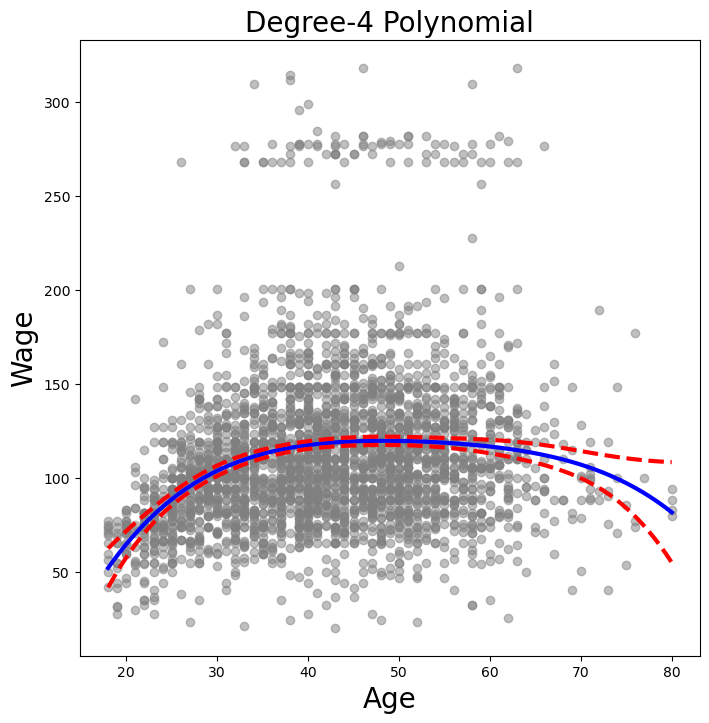

In [9]:
plot_wage_fit(age_df, 
              poly_age,
              'Degree-4 Polynomial');

With  polynomial regression we must decide on the degree of
the polynomial to use. Sometimes we just wing it, and decide to use
second or third degree polynomials, simply to obtain a nonlinear fit. But we can
make such a decision in a more systematic way. One way to do this is through hypothesis
tests, which we demonstrate here. We now fit a series of models ranging from
linear (degree-one) to degree-five polynomials,
and look to determine the simplest model that is sufficient to
explain the relationship between `wage` and `age`. We use the
`anova_lm()`  function, which performs a series of ANOVA
tests.
An \emph{analysis of
  variance}  or ANOVA tests the null
hypothesis that a model $\mathcal{M}_1$ is sufficient to explain the
data against the alternative hypothesis that a more complex model
$\mathcal{M}_2$ is required. The determination is based on an F-test.
To perform the test, the models  $\mathcal{M}_1$ and $\mathcal{M}_2$ must be *nested*:
the space spanned by the predictors in $\mathcal{M}_1$ must be a subspace of the
space spanned by the predictors in $\mathcal{M}_2$. In this case, we
fit five different polynomial
models and sequentially compare the simpler model to the more complex
model.

In [10]:
models = [MS([poly('age', degree=d)]) 
          for d in range(1, 6)]
Xs = [model.fit_transform(Wage) for model in models]
anova_lm(*[sm.OLS(y, X_).fit()
           for X_ in Xs])

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,2998.0,5.022216e+06,0.0,NaN,NaN,NaN
1,2997.0,4.793430e+06,1.0,228786.010128,143.593107,2.363850e-32
2,2996.0,4.777674e+06,1.0,15755.693664,9.888756,1.679202e-03
3,2995.0,4.771604e+06,1.0,6070.152124,3.809813,5.104620e-02
4,2994.0,4.770322e+06,1.0,1282.563017,0.804976,3.696820e-01


Notice the `*` in the `anova_lm()` line above. This
function takes a variable number of non-keyword arguments, in this case fitted models.
When these models are provided as a list (as is done here), it must be
prefixed by `*`.

The p-value comparing the linear `models[0]` to the quadratic
`models[1]` is essentially zero, indicating that a linear
fit is not sufficient. {Indexing starting at zero is confusing for the polynomial degree example, since `models[1]` is quadratic rather than linear!} Similarly the p-value comparing the quadratic
`models[1]` to the cubic `models[2]` is very low (0.0017), so the
quadratic fit is also insufficient. The p-value comparing the cubic
and degree-four polynomials, `models[2]` and `models[3]`, is
approximately 5%, while the degree-five polynomial `models[4]` seems
unnecessary because its p-value is 0.37. Hence, either a cubic or a
quartic polynomial appear to provide a reasonable fit to the data, but
lower- or higher-order models are not justified.

In this case, instead of using the `anova()`  function, we could
have obtained these p-values more succinctly by exploiting the fact
that `poly()`  creates orthogonal polynomials.

In [11]:
summarize(M)

,coef,std err,t,P>|t|
intercept,111.7036,0.729,153.283,0.000
"poly(age, degree=4)[0]",447.0679,39.915,11.201,0.000
"poly(age, degree=4)[1]",-478.3158,39.915,-11.983,0.000
"poly(age, degree=4)[2]",125.5217,39.915,3.145,0.002
"poly(age, degree=4)[3]",-77.9112,39.915,-1.952,0.051


Notice that the p-values are the same, and in fact the square of
the  t-statistics are equal to the F-statistics from the
`anova_lm()`  function;  for example:

In [12]:
(-11.983)**2

143.59228900000002

However, the ANOVA method works whether or not we used orthogonal
polynomials, provided the models are nested. For example, we can use
`anova_lm()`  to compare the following three
models, which all have a linear term in `education` and a
polynomial in `age` of different degrees:

In [13]:
models = [MS(['education', poly('age', degree=d)])
          for d in range(1, 4)]
XEs = [model.fit_transform(Wage)
       for model in models]
anova_lm(*[sm.OLS(y, X_).fit() for X_ in XEs])

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,2997.0,3.902335e+06,0.0,NaN,NaN,NaN
1,2996.0,3.759472e+06,1.0,142862.701185,113.991883,3.838075e-26
2,2995.0,3.753546e+06,1.0,5926.207070,4.728593,2.974318e-02


As an alternative to using hypothesis tests and ANOVA, we could choose
the polynomial degree using cross-validation, as discussed in Chapter 5.

Next we consider the task of predicting whether an individual earns
more than $250,000 per year. We proceed much as before, except
that first we create the appropriate response vector, and then apply
the `glm()`  function using the binomial family in order
to fit a polynomial logistic regression model.

In [14]:
X = poly_age.transform(Wage)
high_earn = Wage['high_earn'] = y > 250 # shorthand
glm = sm.GLM(y > 250,
             X,
             family=sm.families.Binomial())
B = glm.fit()
summarize(B)

,coef,std err,z,P>|z|
intercept,-4.3012,0.345,-12.457,0.000
"poly(age, degree=4)[0]",71.9642,26.133,2.754,0.006
"poly(age, degree=4)[1]",-85.7729,35.929,-2.387,0.017
"poly(age, degree=4)[2]",34.1626,19.697,1.734,0.083
"poly(age, degree=4)[3]",-47.4008,24.105,-1.966,0.049


Once again, we make predictions using the `get_prediction()`  method.

In [15]:
newX = poly_age.transform(age_df)
preds = B.get_prediction(newX)
bands = preds.conf_int(alpha=0.05)

We now plot the estimated relationship.

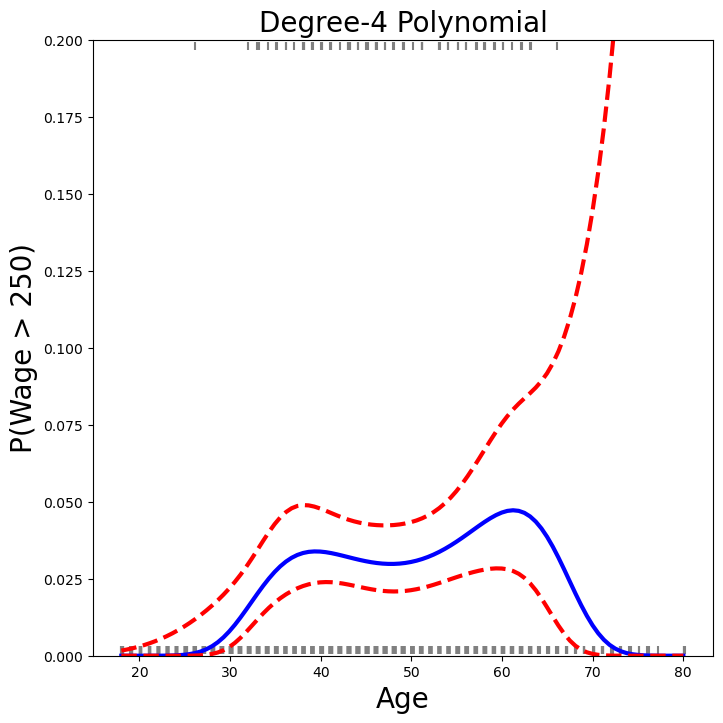

In [16]:
fig, ax = subplots(figsize=(8,8))
rng = np.random.default_rng(0)
ax.scatter(age +
           0.2 * rng.uniform(size=y.shape[0]),
           np.where(high_earn, 0.198, 0.002),
           fc='gray',
           marker='|')
for val, ls in zip([preds.predicted_mean,
                  bands[:,0],
                  bands[:,1]],
                 ['b','r--','r--']):
    ax.plot(age_df.values, val, ls, linewidth=3)
ax.set_title('Degree-4 Polynomial', fontsize=20)
ax.set_xlabel('Age', fontsize=20)
ax.set_ylim([0,0.2])
ax.set_ylabel('P(Wage > 250)', fontsize=20);

We have drawn the `age` values corresponding to the observations with
`wage` values above 250 as gray marks on the top of the plot, and
those with `wage` values below 250 are shown as gray marks on the
bottom of the plot. We added a small amount of noise to jitter
the `age` values a bit so that observations with the same `age`
value do not cover each other up. This type of plot is often called a
*rug plot*.

In order to fit a step function, as discussed in
Section 7.2,   we first use the `pd.qcut()`
function to discretize `age` based on quantiles.  Then  we use `pd.get_dummies()` to create the
columns of the model matrix for this categorical variable. Note that this function will
include *all* columns for a given categorical, rather than the usual approach which drops one
of the levels.

In [17]:
cut_age = pd.qcut(age, 4)
summarize(sm.OLS(y, pd.get_dummies(cut_age)).fit())

,coef,std err,t,P>|t|
"(17.999, 33.75]",94.1584,1.478,63.692,0.0
"(33.75, 42.0]",116.6608,1.470,79.385,0.0
"(42.0, 51.0]",119.1887,1.416,84.147,0.0
"(51.0, 80.0]",116.5717,1.559,74.751,0.0


Here `pd.qcut()`  automatically picked the cutpoints based on the quantiles 25%, 50% and 75%, which results in four regions.  We could also have specified our own
quantiles directly instead of the argument `4`. For cuts not based
on quantiles we would use the `pd.cut()` function.
The function `pd.qcut()` (and `pd.cut()`) returns an ordered categorical variable.
  The regression model then creates a set of
dummy variables for use in the regression. Since `age` is the only variable in the model, the value $94,158.40 is the average salary for those under 33.75 years of
age, and the other coefficients are the average
salary for those in the other age groups.  We can produce
predictions and plots just as we did in the case of the polynomial
fit.

> ✅ <span style="color:red">**Checkpoint** — **Polynomials and step functions**</span>
>
> 1. <span style="color:red">According to the `anova_lm()` table, which degree of polynomial in `age` is sufficient?</span>
> 2. <span style="color:red">Why is the square of the $t$-statistic of the degree-5 coefficient equal to the corresponding $F$-statistic?</span>
> 3. <span style="color:red">What are the four age intervals created by `pd.qcut(age, 4)`?</span>

> **Answers**
>
> 1. The ANOVA suggests that a **cubic or quartic** age polynomial is reasonable. The cubic term is clearly needed; the degree-4 comparison is borderline (about 5%), while the degree-5 term is not justified (p-value about 0.37). Prefer the cubic if choosing the simpler adequate model.
> 2. The degree-5 comparison adds one coefficient. For a single restriction, the partial F-statistic equals the square of the corresponding t-statistic: \(F_{1,df}=t^2\).
> 3. `pd.qcut(age, 4)` forms approximately `(17.999, 33.75]`, `(33.75, 42.0]`, `(42.0, 51.0]`, and `(51.0, 80.0]`. The exact interval labels are printed by `cut_age.cat.categories` in the notebook.

## 3.2 Splines
In order to fit regression splines, we use transforms
from the `ISLP` package. The actual spline
evaluation functions are in the `scipy.interpolate` package;
we have simply wrapped them as transforms
similar to `Poly()` and `PCA()`.

In Section 7.4, we saw
that regression splines can be fit by constructing an appropriate
matrix of basis functions.  The `BSpline()`  function generates the
entire matrix of basis functions for splines with the specified set of
knots. By default, the B-splines produced are cubic. To change the degree, use
the argument `degree`.

In [18]:
bs_ = BSpline(internal_knots=[25,40,60], intercept=True).fit(age)
bs_age = bs_.transform(age)
bs_age.shape

(3000, 7)

This results in a seven-column matrix, which is what is expected for a cubic-spline basis with 3 interior knots.
We can form this same matrix using the `bs()` object,
which facilitates adding this to a model-matrix builder (as in `poly()` versus its workhorse `Poly()`) described in Section 7.8.1.

We now fit a cubic spline model to the `Wage`  data.

In [19]:
bs_age = MS([bs('age', internal_knots=[25,40,60])])
Xbs = bs_age.fit_transform(Wage)
M = sm.OLS(y, Xbs).fit()
summarize(M)

,coef,std err,t,P>|t|
intercept,60.4937,9.460,6.394,0.000
"bs(age, internal_knots=[25, 40, 60])[0]",3.9805,12.538,0.317,0.751
"bs(age, internal_knots=[25, 40, 60])[1]",44.6310,9.626,4.636,0.000
"bs(age, internal_knots=[25, 40, 60])[2]",62.8388,10.755,5.843,0.000
"bs(age, internal_knots=[25, 40, 60])[3]",55.9908,10.706,5.230,0.000
"bs(age, internal_knots=[25, 40, 60])[4]",50.6881,14.402,3.520,0.000
"bs(age, internal_knots=[25, 40, 60])[5]",16.6061,19.126,0.868,0.385


The column names are a little cumbersome, and have caused us to truncate the printed summary. They can be set on construction using the `name` argument as follows.

In [20]:
bs_age = MS([bs('age',
                internal_knots=[25,40,60],
                name='bs(age)')])
Xbs = bs_age.fit_transform(Wage)
M = sm.OLS(y, Xbs).fit()
summarize(M)

,coef,std err,t,P>|t|
intercept,60.4937,9.460,6.394,0.000
bs(age)[0],3.9805,12.538,0.317,0.751
bs(age)[1],44.6310,9.626,4.636,0.000
bs(age)[2],62.8388,10.755,5.843,0.000
bs(age)[3],55.9908,10.706,5.230,0.000
bs(age)[4],50.6881,14.402,3.520,0.000
bs(age)[5],16.6061,19.126,0.868,0.385


Notice that there are 6 spline coefficients rather than 7. This is because, by default,
`bs()` assumes `intercept=False`, since we typically have an overall intercept in the model.
So it generates the spline basis with the given knots,  and then discards one of the basis functions to account for the intercept.

We could also use the `df` (degrees of freedom) option to
specify the complexity of the spline.  We see above that with 3 knots,
the spline basis has 6 columns or degrees of freedom.  When we specify
`df=6` rather than the actual knots, `bs()` will produce a
spline with 3 knots chosen at uniform quantiles of the training data.
We can see these chosen knots most easily using `Bspline()` directly:

In [21]:
BSpline(df=6).fit(age).internal_knots_

array([33.75, 42.  , 51.  ])

 When asking for six degrees of freedom,
the transform chooses knots at ages 33.75, 42.0, and 51.0,
which correspond to the 25th, 50th, and 75th percentiles of
`age`.

When using B-splines we need not limit ourselves to cubic polynomials
(i.e. `degree=3`). For instance, using `degree=0` results
in piecewise constant functions, as in our example with
`pd.qcut()` above.

In [22]:
bs_age0 = MS([bs('age',
                 df=3, 
                 degree=0)]).fit(Wage)
Xbs0 = bs_age0.transform(Wage)
summarize(sm.OLS(y, Xbs0).fit())

,coef,std err,t,P>|t|
intercept,94.1584,1.478,63.687,0.0
"bs(age, df=3, degree=0)[0]",22.3490,2.152,10.388,0.0
"bs(age, df=3, degree=0)[1]",24.8076,2.044,12.137,0.0
"bs(age, df=3, degree=0)[2]",22.7814,2.087,10.917,0.0


This fit should be compared with cell [15] where we use `qcut()`
to create four bins by cutting at the 25%, 50% and 75% quantiles of
`age`.  Since we specified `df=3` for degree-zero splines here, there will also be
knots at the same three quantiles. Although the coefficients appear different, we
see that this is a result of the different coding. For example, the
first coefficient is identical in both cases, and is the mean response
in the first bin. For the second coefficient, we have
$94.158 + 22.349 = 116.507 \approx 116.611$, the latter being the mean
in the second bin in cell [15]. Here the intercept is coded by a column
of ones, so the second, third and fourth coefficients are increments
for those bins. Why is the sum not exactly the same? It turns out that
the `qcut()` uses $\leq$, while `bs()` uses $<$ when
deciding bin membership.

In order to fit a natural spline, we use the `NaturalSpline()`
transform with the corresponding helper `ns()`.  Here we fit a natural spline with five
degrees of freedom (excluding the intercept) and plot the results.

In [23]:
ns_age = MS([ns('age', df=5)]).fit(Wage)
M_ns = sm.OLS(y, ns_age.transform(Wage)).fit()
summarize(M_ns)

,coef,std err,t,P>|t|
intercept,60.4752,4.708,12.844,0.000
"ns(age, df=5)[0]",61.5267,4.709,13.065,0.000
"ns(age, df=5)[1]",55.6912,5.717,9.741,0.000
"ns(age, df=5)[2]",46.8184,4.948,9.463,0.000
"ns(age, df=5)[3]",83.2036,11.918,6.982,0.000
"ns(age, df=5)[4]",6.8770,9.484,0.725,0.468


We now plot the natural spline using our plotting function.

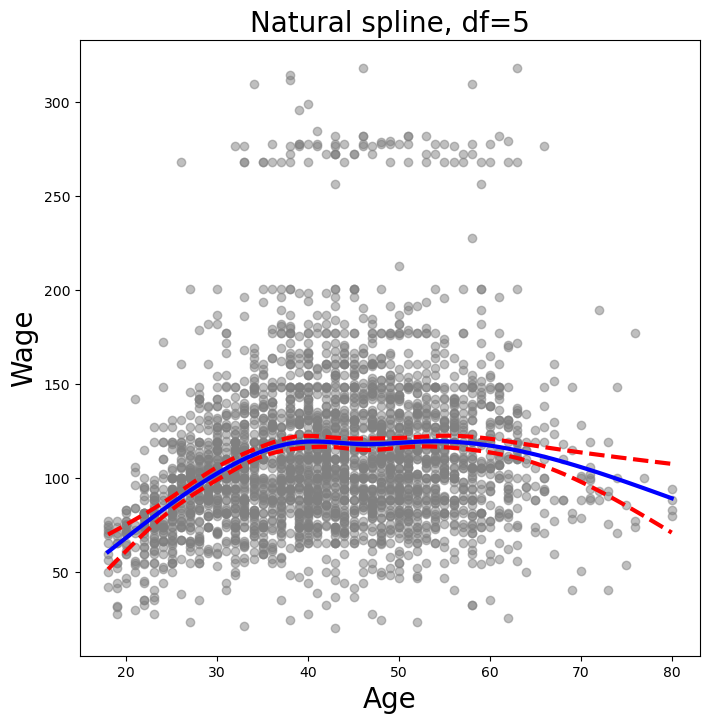

In [24]:
plot_wage_fit(age_df,
              ns_age,
              'Natural spline, df=5');

> ✅ <span style="color:red">**Checkpoint** — **Splines**</span>
>
> 1. <span style="color:red">How many columns does `bs('age', internal_knots=[25, 40, 60])` create and why?</span>
> 2. <span style="color:red">Where does `BSpline(df=6)` put its knots?</span>
> 3. <span style="color:red">Compare the confidence bands of the degree-4 polynomial and of the natural spline at the extremes of `age`.</span>

> **Answers**
>
> 1. It creates **6 columns**: a cubic B-spline basis with 3 interior knots has 7 basis functions when the intercept is included; `bs()` defaults to `intercept=False` and drops one column because the regression already includes an intercept.
> 2. `BSpline(df=6)` places its three interior knots at the 25th, 50th, and 75th percentiles of age: **33.75, 42.0, and 51.0** in this dataset.
> 3. At the boundaries, the degree-4 polynomial can bend more sharply and its confidence bands can widen or behave less stably. The natural spline is constrained to be linear beyond its boundary knots, usually giving more stable tail behaviour. The bands may still widen where observations are sparse; compare the actual plots rather than assuming the natural-spline bands are always narrower.

## 3.3 Smoothing Splines and GAMs
A smoothing spline is a special case of a GAM with squared-error loss
and a single feature. To fit GAMs in `Python` we will use the
`pygam` package which can be installed via `pip install pygam`. The
estimator `LinearGAM()` uses squared-error loss.
The GAM is specified by associating each column
of a model matrix with a particular smoothing operation:
`s` for smoothing spline; `l` for linear, and `f` for factor or categorical variables.
The argument `0` passed to `s` below indicates that this smoother will
apply to the first column of a feature matrix. Below, we pass it a
matrix with a single column: `X_age`. The argument `lam` is the penalty parameter $\lambda$ as discussed in Section 7.5.2.

In [25]:
X_age = np.asarray(age).reshape((-1,1))
gam = LinearGAM(s_gam(0, lam=0.6))
gam.fit(X_age, y)

LinearGAM(callbacks=[Deviance(), Diffs()], fit_intercept=True, 
   max_iter=100, scale=None, terms=s(0) + intercept, tol=0.0001, 
   verbose=False)

The `pygam` library generally expects a matrix of features so we reshape `age` to be a matrix (a two-dimensional array) instead
of a vector (i.e. a one-dimensional array). The `-1` in the call to the `reshape()` method tells `numpy` to impute the
size of that dimension based on the remaining entries of the shape tuple.

Let’s investigate how the fit changes with the smoothing parameter `lam`.
The function `np.logspace()` is similar to `np.linspace()` but spaces points
evenly on the log-scale. Below we vary `lam` from $10^{-2}$ to $10^6$.

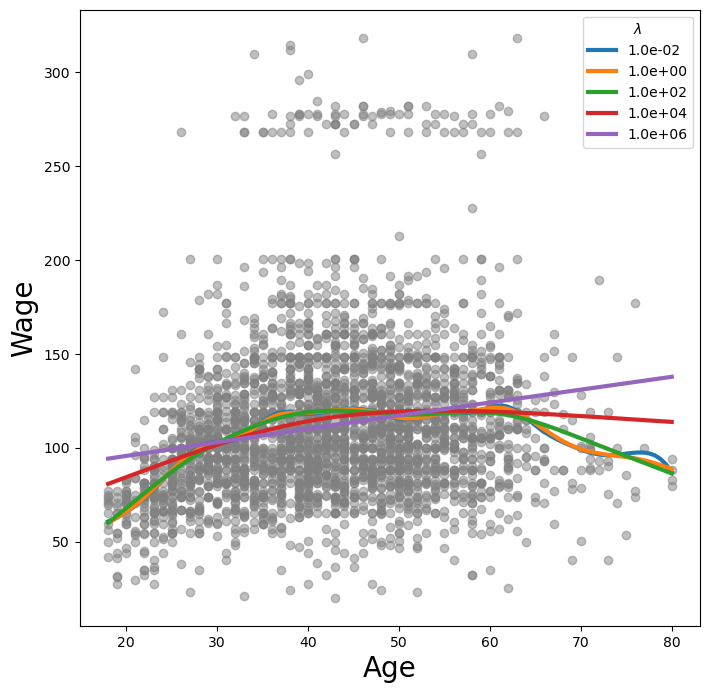

In [26]:
fig, ax = subplots(figsize=(8,8))
ax.scatter(age, y, facecolor='gray', alpha=0.5)
for lam in np.logspace(-2, 6, 5):
    gam = LinearGAM(s_gam(0, lam=lam)).fit(X_age, y)
    ax.plot(age_grid,
            gam.predict(age_grid),
            label='{:.1e}'.format(lam),
            linewidth=3)
ax.set_xlabel('Age', fontsize=20)
ax.set_ylabel('Wage', fontsize=20);
ax.legend(title='$\lambda$');

The `pygam` package can perform a search for an optimal smoothing parameter.

  0% (0 of 11) |                         | Elapsed Time: 0:00:00 ETA:  --:--:--
  9% (1 of 11) |##                       | Elapsed Time: 0:00:00 ETA:   0:00:01
 36% (4 of 11) |#########                | Elapsed Time: 0:00:00 ETA:   0:00:00
 63% (7 of 11) |###############          | Elapsed Time: 0:00:00 ETA:   0:00:00
 90% (10 of 11) |#####################   | Elapsed Time: 0:00:00 ETA:   0:00:00
100% (11 of 11) |########################| Elapsed Time: 0:00:00 Time:  0:00:00


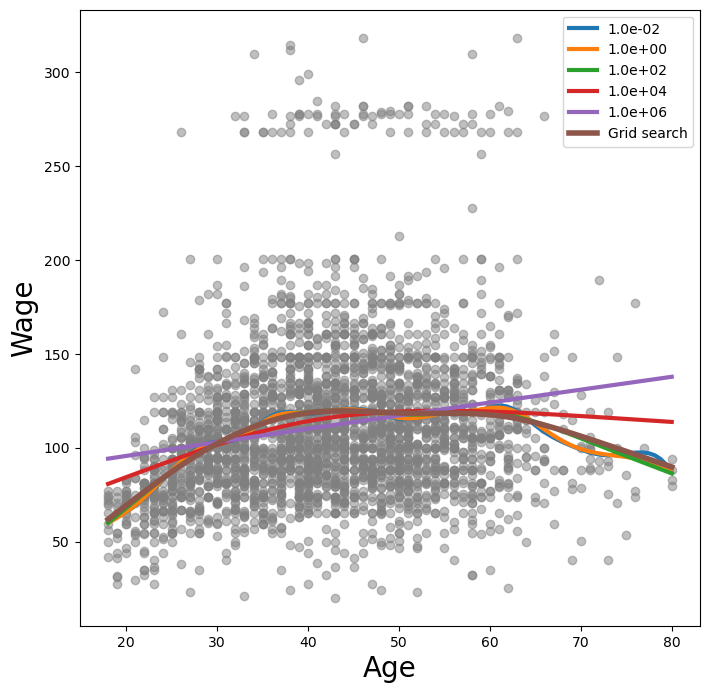

In [27]:
gam_opt = gam.gridsearch(X_age, y)
ax.plot(age_grid,
        gam_opt.predict(age_grid),
        label='Grid search',
        linewidth=4)
ax.legend()
fig

Alternatively, we can fix the degrees of freedom of the smoothing
spline using a function included in the `ISLP.pygam` package. Below we
find a value of $\lambda$ that gives us roughly four degrees of
freedom. We note here that these degrees of freedom include the
unpenalized intercept and linear term of the smoothing spline, hence there are at least two
degrees of freedom.

In [28]:
age_term = gam.terms[0]
lam_4 = approx_lam(X_age, age_term, 4)
age_term.lam = lam_4
degrees_of_freedom(X_age, age_term)

np.float64(4.000000100005237)

Let’s vary the degrees of freedom in a similar plot to above. We choose the degrees of freedom
as the desired degrees of freedom plus one to account for the fact that these smoothing
splines always have an intercept term. Hence, a value of one for `df` is just a linear fit.

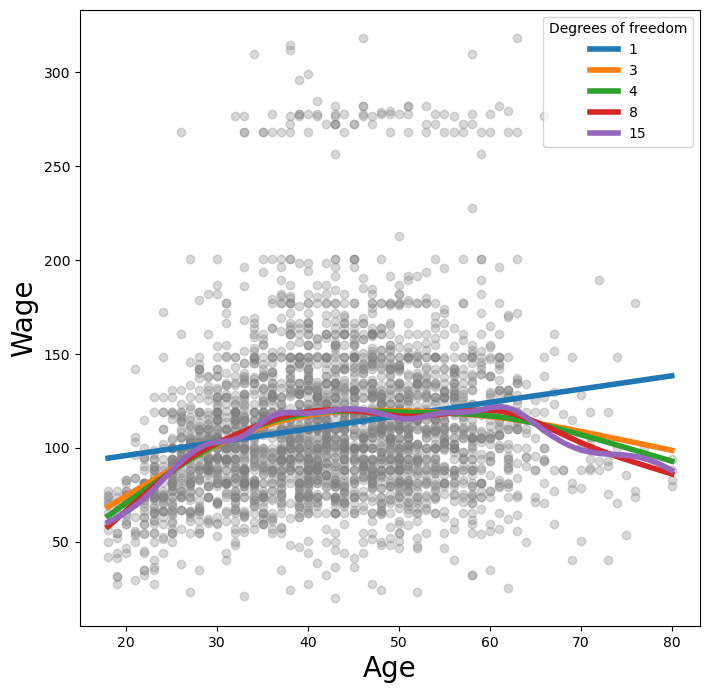

In [29]:
fig, ax = subplots(figsize=(8,8))
ax.scatter(X_age,
           y,
           facecolor='gray',
           alpha=0.3)
for df in [1,3,4,8,15]:
    lam = approx_lam(X_age, age_term, df+1)
    age_term.lam = lam
    gam.fit(X_age, y)
    ax.plot(age_grid,
            gam.predict(age_grid),
            label='{:d}'.format(df),
            linewidth=4)
ax.set_xlabel('Age', fontsize=20)
ax.set_ylabel('Wage', fontsize=20);
ax.legend(title='Degrees of freedom');

### Additive Models with Several Terms
The strength of generalized additive models lies in their ability to fit multivariate regression models with more flexibility than linear models. We demonstrate two approaches: the first in a more manual fashion using natural splines and piecewise constant functions, and the second  using the `pygam` package and smoothing splines.

We now fit a GAM by hand to predict
`wage` using natural spline functions of `year` and `age`,
treating `education` as a qualitative predictor, as in (7.16).
Since this is just a big linear regression model
using an appropriate choice of basis functions, we can simply do this
using the `sm.OLS()`  function.

We will build the model matrix in a more manual fashion here, since we wish
to access the pieces separately when constructing partial dependence plots.

In [30]:
ns_age = NaturalSpline(df=4).fit(age)
ns_year = NaturalSpline(df=5).fit(Wage['year'])
Xs = [ns_age.transform(age),
      ns_year.transform(Wage['year']),
      pd.get_dummies(Wage['education']).values]
X_bh = np.hstack(Xs)
gam_bh = sm.OLS(y, X_bh).fit()

Here the function `NaturalSpline()` is the workhorse supporting
the `ns()` helper function.  We chose to use all columns of the
indicator matrix for the categorical variable `education`, making an intercept redundant.
Finally, we stacked the three component matrices horizontally to form the model matrix `X_bh`.

We now show how to construct partial dependence plots for each of the terms in our rudimentary GAM. We can do this by hand,
given grids for `age` and `year`.
 We simply predict with new $X$ matrices, fixing all but one of the features at a time.

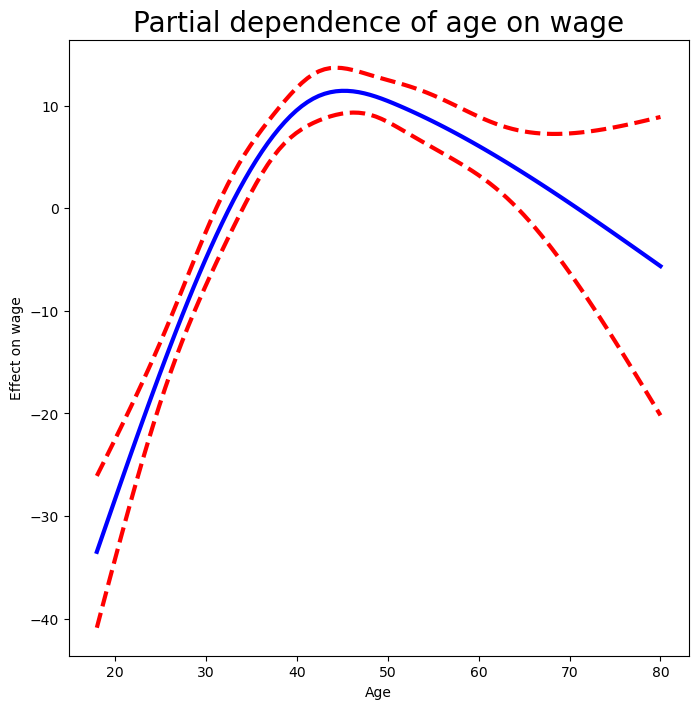

In [31]:
age_grid = np.linspace(age.min(),
                       age.max(),
                       100)
X_age_bh = X_bh.copy()[:100]
X_age_bh[:] = X_bh[:].mean(0)[None,:]
X_age_bh[:,:4] = ns_age.transform(age_grid)
preds = gam_bh.get_prediction(X_age_bh)
bounds_age = preds.conf_int(alpha=0.05)
partial_age = preds.predicted_mean
center = partial_age.mean()
partial_age -= center
bounds_age -= center
fig, ax = subplots(figsize=(8,8))
ax.plot(age_grid, partial_age, 'b', linewidth=3)
ax.plot(age_grid, bounds_age[:,0], 'r--', linewidth=3)
ax.plot(age_grid, bounds_age[:,1], 'r--', linewidth=3)
ax.set_xlabel('Age')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of age on wage', fontsize=20);

Let's explain in some detail what we did above. The idea is to create a new prediction matrix, where all but the columns belonging to `age` are constant (and set to  their training-data means). The four columns for `age` are filled in with the natural spline basis evaluated at the 100 values in `age_grid`.

* We made a grid of length 100 in `age`, and created a matrix `X_age_bh` with 100 rows and the same number of columns as `X_bh`.
* We replaced every row of this matrix with the column means of the original.
* We then replace just the first four columns representing `age` with the natural spline basis computed at the values in `age_grid`.

The remaining steps should by now be familiar.

We also look at the effect of `year` on `wage`; the process is the same.

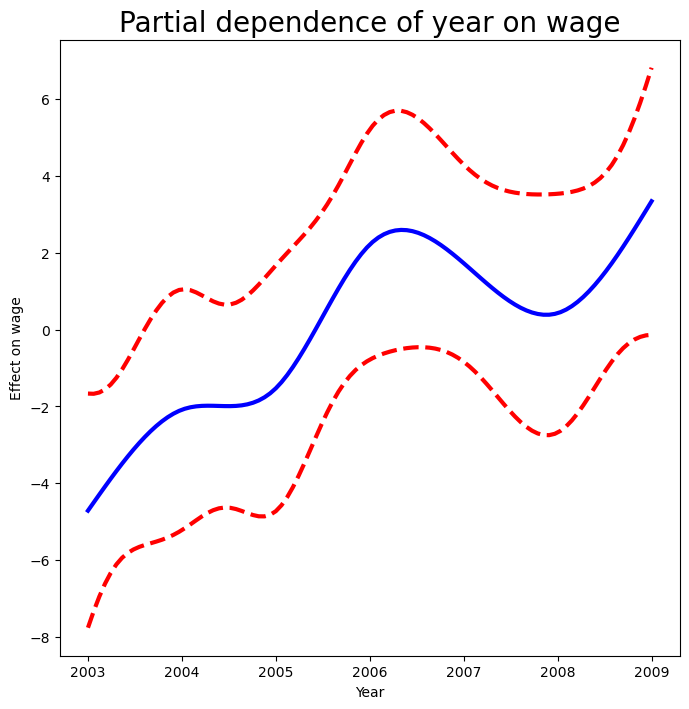

In [32]:
year_grid = np.linspace(2003, 2009, 100)
year_grid = np.linspace(Wage['year'].min(),
                        Wage['year'].max(),
                        100)
X_year_bh = X_bh.copy()[:100]
X_year_bh[:] = X_bh[:].mean(0)[None,:]
X_year_bh[:,4:9] = ns_year.transform(year_grid)
preds = gam_bh.get_prediction(X_year_bh)
bounds_year = preds.conf_int(alpha=0.05)
partial_year = preds.predicted_mean
center = partial_year.mean()
partial_year -= center
bounds_year -= center
fig, ax = subplots(figsize=(8,8))
ax.plot(year_grid, partial_year, 'b', linewidth=3)
ax.plot(year_grid, bounds_year[:,0], 'r--', linewidth=3)
ax.plot(year_grid, bounds_year[:,1], 'r--', linewidth=3)
ax.set_xlabel('Year')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of year on wage', fontsize=20);

We now fit the model (7.16)  using smoothing splines rather
than natural splines.  All of the
terms in  (7.16)  are fit simultaneously, taking each other
into account to explain the response. The `pygam` package only works with matrices, so we must convert
the categorical series `education` to its array representation, which can be found
with the `cat.codes` attribute of `education`. As `year` only has 7 unique values, we
use only seven basis functions for it.

In [33]:
gam_full = LinearGAM(s_gam(0) +
                     s_gam(1, n_splines=7) +
                     f_gam(2, lam=0))
Xgam = np.column_stack([age,
                        Wage['year'],
                        Wage['education'].cat.codes])
gam_full = gam_full.fit(Xgam, y)

The two `s_gam()` terms result in smoothing spline fits, and use a default value for $\lambda$  (`lam=0.6`), which is somewhat arbitrary. For the categorical term `education`, specified using a `f_gam()` term,  we specify `lam=0` to avoid any shrinkage.
We produce the partial dependence plot in `age` to see the effect of these choices.

The values for the plot
are generated by the `pygam` package. We provide a `plot_gam()`
function for partial-dependence plots in `ISLP.pygam`, which makes this job easier than in our last example with natural splines.

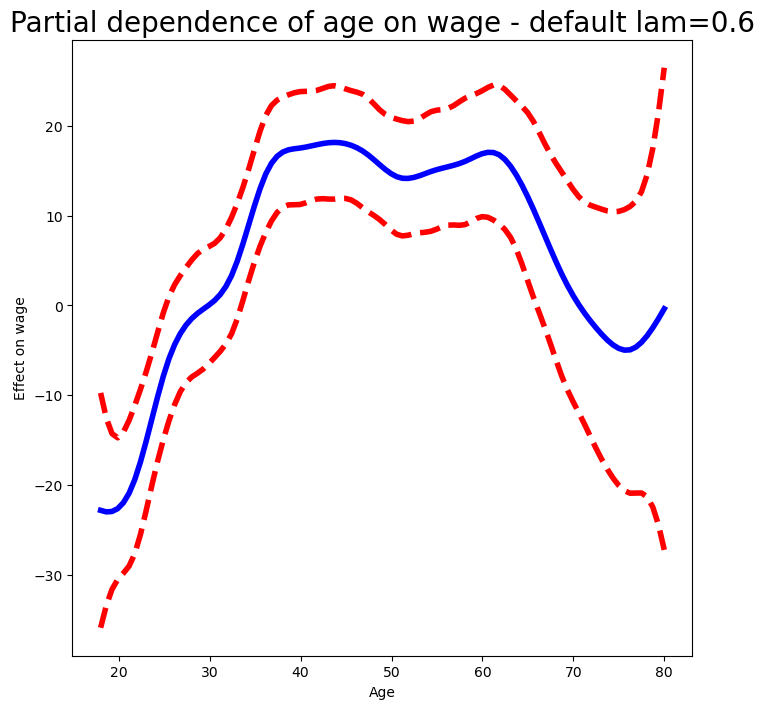

In [34]:
fig, ax = subplots(figsize=(8,8))
plot_gam(gam_full, 0, ax=ax)
ax.set_xlabel('Age')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of age on wage - default lam=0.6', fontsize=20);

We see that the function is somewhat wiggly. It is more natural to specify the `df` than a value for `lam`.
We refit a GAM using four degrees of freedom each for
`age` and  `year`. Recall that the addition of one below takes into account the intercept
of the smoothing spline.

In [35]:
age_term = gam_full.terms[0]
age_term.lam = approx_lam(Xgam, age_term, df=4+1)
year_term = gam_full.terms[1]
year_term.lam = approx_lam(Xgam, year_term, df=4+1)
gam_full = gam_full.fit(Xgam, y)

Note that updating `age_term.lam` above updates it in `gam_full.terms[0]` as well! Likewise for `year_term.lam`.

Repeating the plot for `age`, we see that it is much smoother.
We also produce the plot for `year`.

Text(0.5, 1.0, 'Partial dependence of year on wage')

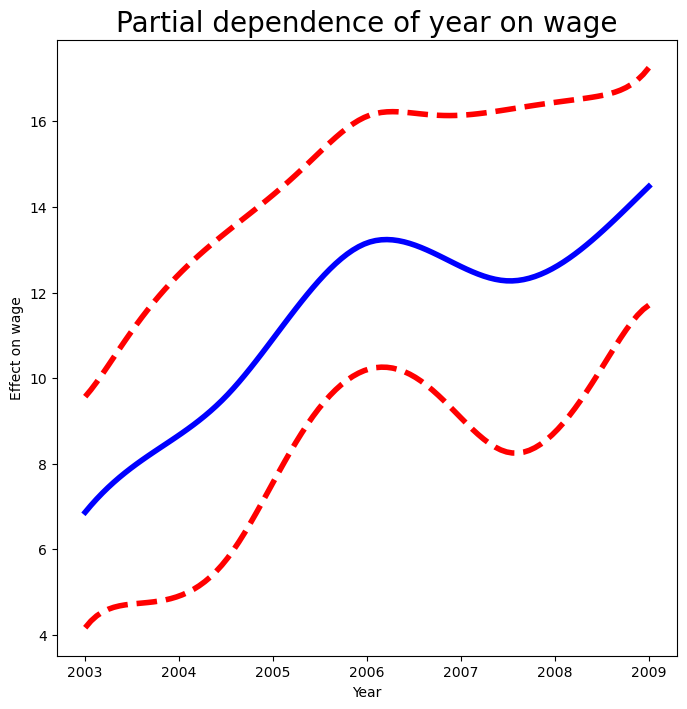

In [36]:
fig, ax = subplots(figsize=(8,8))
plot_gam(gam_full,
         1,
         ax=ax)
ax.set_xlabel('Year')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of year on wage', fontsize=20)

Finally we plot `education`, which is categorical. The partial dependence plot is different, and more suitable for the set of fitted constants for each level of this variable.

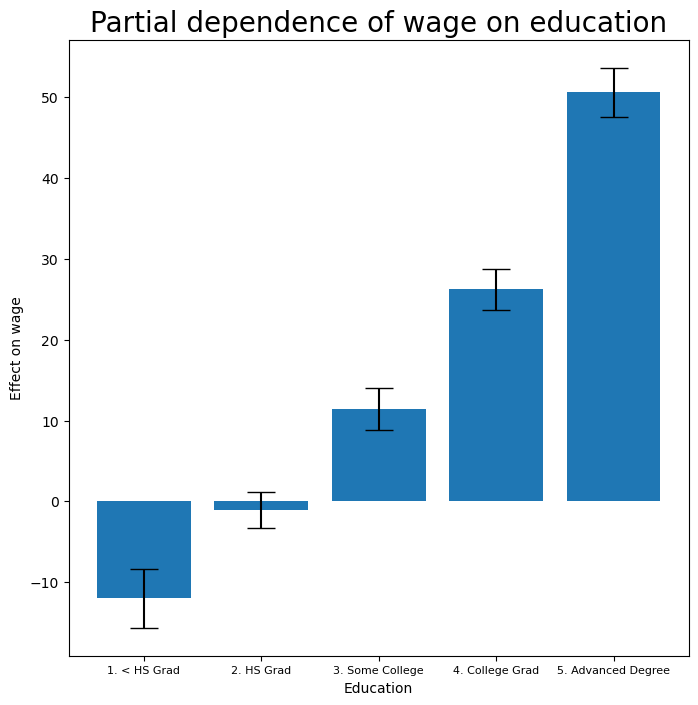

In [37]:
fig, ax = subplots(figsize=(8, 8))
ax = plot_gam(gam_full, 2)
ax.set_xlabel('Education')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of wage on education',
             fontsize=20);
ax.set_xticklabels(Wage['education'].cat.categories, fontsize=8);

### ANOVA Tests for Additive Models
In all of our models, the function of `year` looks rather linear. We can
perform a series of ANOVA tests in order to determine which of these
three models is best: a GAM that excludes `year` ($\mathcal{M}_1$),
a GAM that uses a linear function of `year` ($\mathcal{M}_2$), or a
GAM that uses a spline function of `year` ($\mathcal{M}_3$).

In [38]:
gam_0 = LinearGAM(age_term + f_gam(2, lam=0))
gam_0.fit(Xgam, y)
gam_linear = LinearGAM(age_term +
                       l_gam(1, lam=0) +
                       f_gam(2, lam=0))
gam_linear.fit(Xgam, y)

LinearGAM(callbacks=[Deviance(), Diffs()], fit_intercept=True, 
   max_iter=100, scale=None, terms=s(0) + l(1) + f(2) + intercept, 
   tol=0.0001, verbose=False)

Notice our use of `age_term` in the expressions above. We do this because
earlier we set the value for `lam` in this term to achieve four degrees of freedom.

To directly assess the effect of `year` we run an ANOVA on the
three models fit above.

In [39]:
anova_gam(gam_0, gam_linear, gam_full)

,deviance,df,deviance_diff,df_diff,F,pvalue
0,105402.432206,2991.004005,NaN,NaN,NaN,NaN
1,105134.624170,2990.005190,267.808037,0.998815,7.625329,0.016210
2,105030.684668,2987.007254,103.939502,2.997936,0.986003,0.429637


 We find that there is compelling evidence that a GAM with a linear
function in `year` is better than a GAM that does not include
`year` at all ($p$-value= 0.002). However, there is no
evidence that a non-linear function of `year` is needed
($p$-value=0.435).  In other words, based on the results of this
ANOVA, $\mathcal{M}_2$ is preferred.

We can repeat the same process for `age` as well. We see there is very clear evidence that
a non-linear term is required for `age`.

In [40]:
gam_0 = LinearGAM(year_term +
                  f_gam(2, lam=0))
gam_linear = LinearGAM(l_gam(0, lam=0) +
                       year_term +
                       f_gam(2, lam=0))
gam_0.fit(Xgam, y)
gam_linear.fit(Xgam, y)
anova_gam(gam_0, gam_linear, gam_full)

,deviance,df,deviance_diff,df_diff,F,pvalue
0,109043.809955,2991.000589,NaN,NaN,NaN,NaN
1,107295.111571,2990.000704,1748.698385,0.999884,49.737638,0.000009
2,105030.684668,2987.007254,2264.426903,2.993450,21.513266,0.000026


There is a (verbose) `summary()` method for the GAM fit.

In [41]:
gam_full.summary()

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     12.9927
Link Function:                     IdentityLink Log Likelihood:                                 -14930.261
Number of Samples:                         3000 AIC:                                            29888.5074
                                                AICc:                                            29888.648
                                                GCV:                                             1246.1129
                                                Scale:                                             35.1625
                                                Pseudo R-Squared:                                   0.2928
Feature Function                  Lam

C:\Users\Admin\AppData\Local\Temp\ipykernel_35248\3870570873.py:1: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam_full.summary()


We can make predictions from `gam` objects, just like from
`lm` objects, using the `predict()`  method for the class
`gam`.  Here we make predictions on the training set.

In [42]:
Yhat = gam_full.predict(Xgam)

In order to fit a logistic regression GAM, we use `LogisticGAM()`
from `pygam`.

In [43]:
gam_logit = LogisticGAM(age_term + 
                        l_gam(1, lam=0) +
                        f_gam(2, lam=0))
gam_logit.fit(Xgam, high_earn)

LogisticGAM(callbacks=[Deviance(), Diffs(), Accuracy()], 
   fit_intercept=True, max_iter=100, 
   terms=s(0) + l(1) + f(2) + intercept, tol=0.0001, verbose=False)

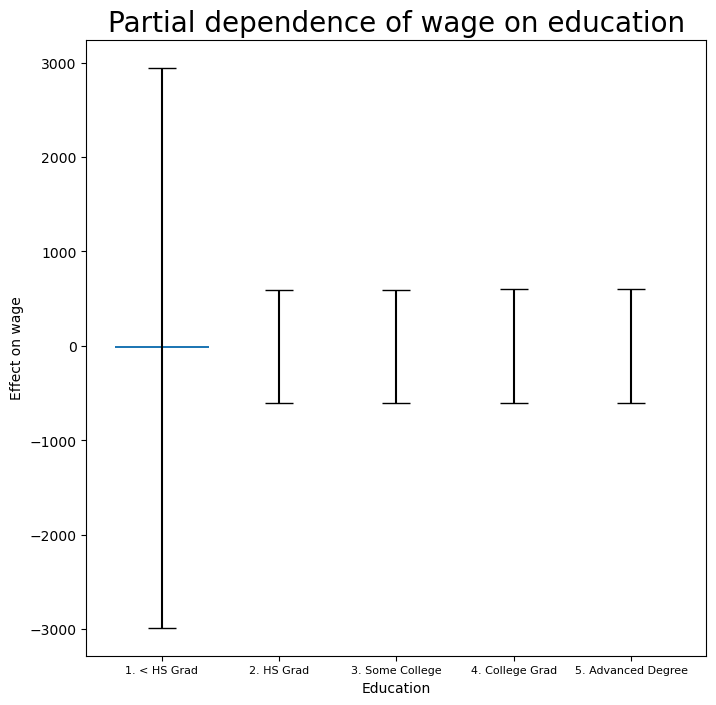

In [44]:
fig, ax = subplots(figsize=(8, 8))
ax = plot_gam(gam_logit, 2)
ax.set_xlabel('Education')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of wage on education',
             fontsize=20);
ax.set_xticklabels(Wage['education'].cat.categories, fontsize=8);

The model seems to be very flat, with especially high error bars for the first category.
Let's look at the data a bit more closely.

In [45]:
pd.crosstab(Wage['high_earn'], Wage['education'])

education,1. < HS Grad,2. HS Grad,3. Some College,4. College Grad,5. Advanced Degree
high_earn,,,,,
False,268,966,643,663,381
True,0,5,7,22,45


We see that there are no high earners in the first category of
education, meaning that the model will have a hard time fitting.  We
will fit a logistic regression GAM excluding all observations falling into this
category. This provides more sensible results.

To do so,
we could subset the model matrix, though this will not remove the
column from `Xgam`. While we can deduce which column corresponds
to this feature, for reproducibility’s sake we reform the model matrix
on this smaller subset.

In [46]:
only_hs = Wage['education'] == '1. < HS Grad'
Wage_ = Wage.loc[~only_hs]
Xgam_ = np.column_stack([Wage_['age'],
                         Wage_['year'],
                         Wage_['education'].cat.codes-1])
high_earn_ = Wage_['high_earn']

In the second-to-last line above, we subtract one  from the codes of the category, due to a bug in `pygam`. It just relabels
the education values and hence has no effect on the fit.

We now fit the model.

In [47]:
gam_logit_ = LogisticGAM(age_term +
                         year_term +
                         f_gam(2, lam=0))
gam_logit_.fit(Xgam_, high_earn_)

LogisticGAM(callbacks=[Deviance(), Diffs(), Accuracy()], 
   fit_intercept=True, max_iter=100, 
   terms=s(0) + s(1) + f(2) + intercept, tol=0.0001, verbose=False)

Let’s look at the effect of `education`, `year` and `age` on high earner status now that we’ve
removed those observations.

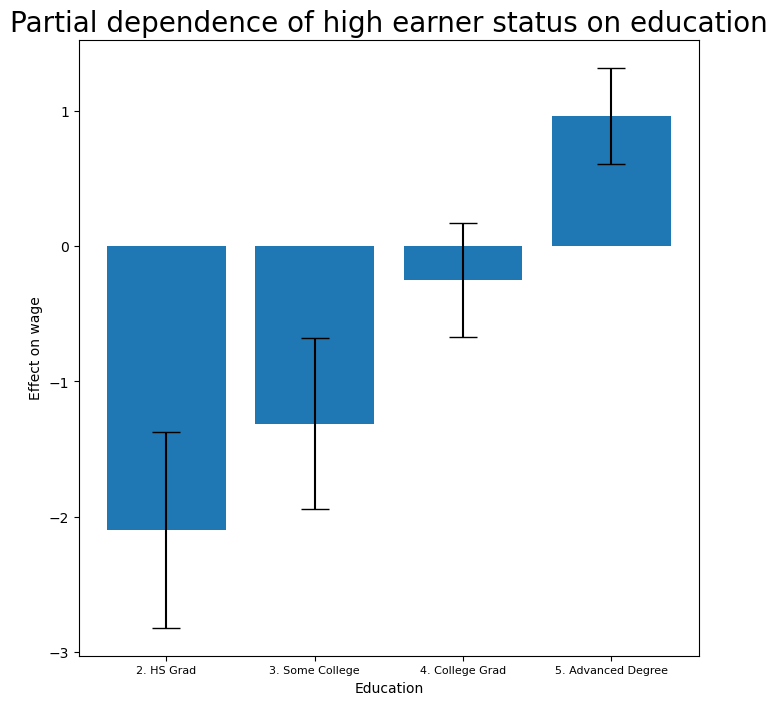

In [48]:
fig, ax = subplots(figsize=(8, 8))
ax = plot_gam(gam_logit_, 2)
ax.set_xlabel('Education')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of high earner status on education', fontsize=20);
ax.set_xticklabels(Wage['education'].cat.categories[1:],
                   fontsize=8);

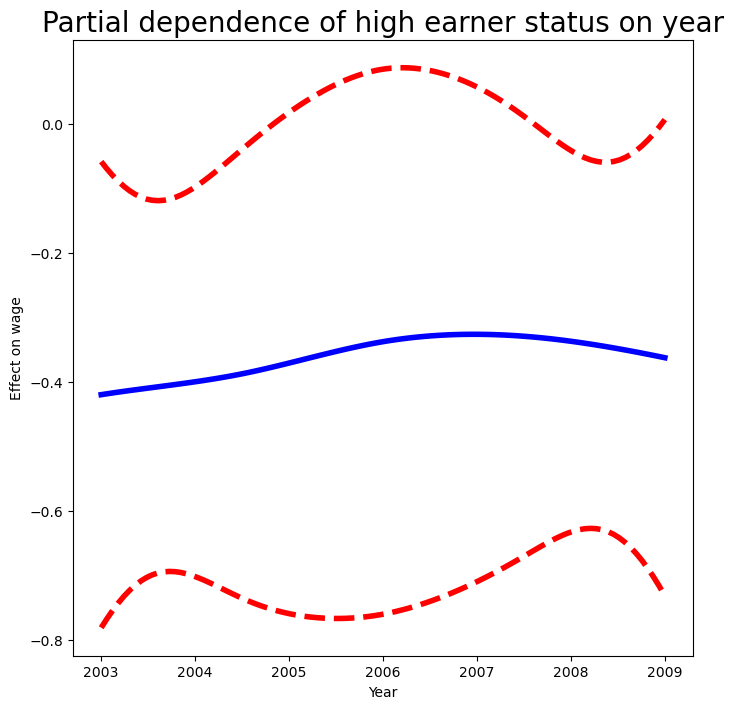

In [49]:
fig, ax = subplots(figsize=(8, 8))
ax = plot_gam(gam_logit_, 1)
ax.set_xlabel('Year')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of high earner status on year',
             fontsize=20);

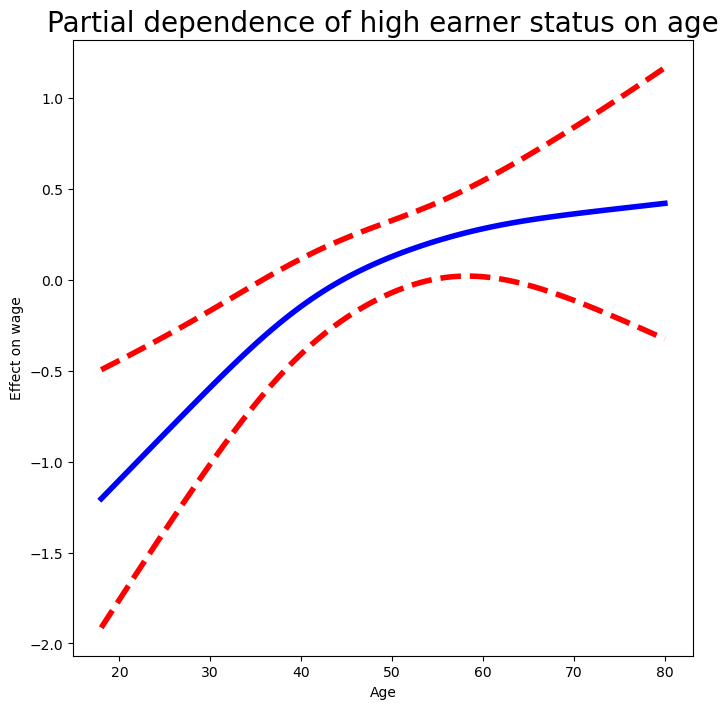

In [50]:
fig, ax = subplots(figsize=(8, 8))
ax = plot_gam(gam_logit_, 0)
ax.set_xlabel('Age')
ax.set_ylabel('Effect on wage')
ax.set_title('Partial dependence of high earner status on age', fontsize=20);

> ✅ <span style="color:red">**Checkpoint** — **GAMs**</span>
>
> 1. <span style="color:red">Which `anova_gam()` comparison tells you whether `year` needs a non-linear function?</span>
> 2. <span style="color:red">Why was the education level "< HS Grad" removed before fitting the logistic GAM?</span>

> **Answers**
>
> 1. Compare **M₂ (linear year)** with **M₃ (smooth year)** in `anova_gam(gam_0, gam_linear, gam_full)`. The notebook reports p = 0.435 for this comparison, so there is no evidence that year needs a nonlinear smooth; the linear year term is preferred. The M₁-to-M₂ comparison instead tests whether year should be included at all.
> 2. The `"< HS Grad"` education category has **no high earners** in the data (`pd.crosstab` shows zero observations with `high_earn=True`). This creates complete separation for that category in logistic regression and can produce unstable or poorly identified estimates. Excluding it allows the remaining education effects to be estimated more sensibly.

## 3.4 Local Regression
We illustrate the use of local regression using  the `lowess()`
function from `sm.nonparametric`. Some implementations of
GAMs allow terms to be local regression operators; this is not the case in `pygam`.

Here we fit local linear regression models using spans of 0.2
and 0.5; that is, each neighborhood consists of 20% or 50% of
the observations. As expected, using a span of 0.5 is smoother than 0.2.

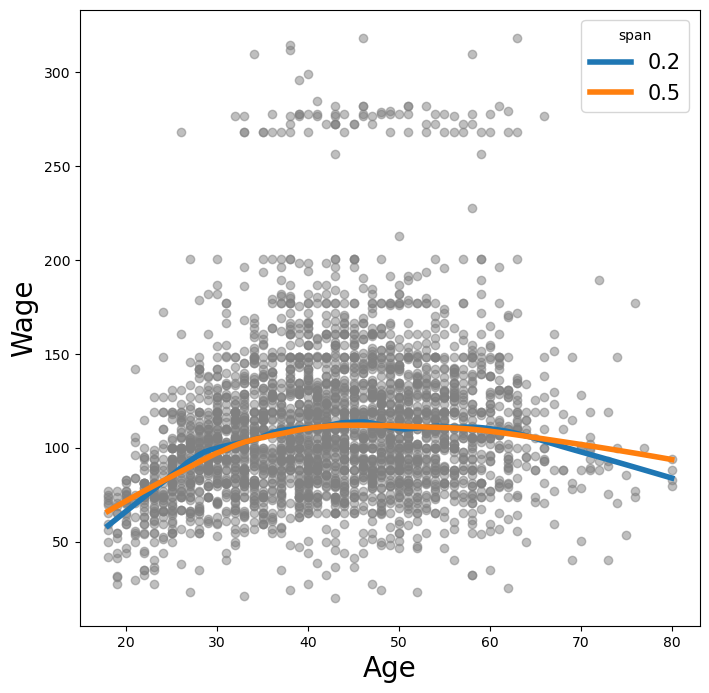

In [51]:
lowess = sm.nonparametric.lowess
fig, ax = subplots(figsize=(8,8))
ax.scatter(age, y, facecolor='gray', alpha=0.5)
for span in [0.2, 0.5]:
    fitted = lowess(y,
                    age,
                    frac=span,
                    xvals=age_grid)
    ax.plot(age_grid,
            fitted,
            label='{:.1f}'.format(span),
            linewidth=4)
ax.set_xlabel('Age', fontsize=20)
ax.set_ylabel('Wage', fontsize=20);
ax.legend(title='span', fontsize=15);

## <span style="color:red">3.5 Extra worked examples</span>

<span style="color:red">**Worked Example 1 – Choosing the polynomial degree by 10-fold cross-validation.** `anova_lm()` compares nested models with hypothesis tests; cross-validation estimates the test error directly.</span>

CV errors: [1677.2 1601.4 1596.2 1595.1 1595.1 1594.8 1595.1 1595.8 1594.3 1595.5]
best degree: 9


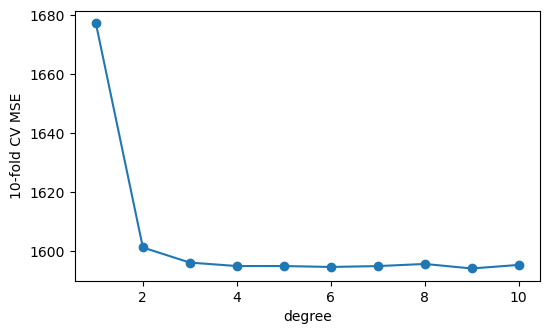

In [52]:
# [ADDED] worked example – run this cell
from sklearn.model_selection import KFold
kf = KFold(10, shuffle=True, random_state=1)
cv_err = []
for d in range(1, 11):
    fold_mse = []
    for tr, te in kf.split(Wage):
        spec = MS([poly('age', degree=d)]).fit(Wage.iloc[tr])
        fit_d = sm.OLS(y.iloc[tr], spec.transform(Wage.iloc[tr])).fit()
        fold_mse.append(np.mean((y.iloc[te] - fit_d.predict(spec.transform(Wage.iloc[te])))**2))
    cv_err.append(np.mean(fold_mse))
fig, ax = subplots(figsize=(6, 3.5))
ax.plot(range(1, 11), cv_err, 'o-'); ax.set_xlabel('degree'); ax.set_ylabel('10-fold CV MSE')
print('CV errors:', np.round(cv_err, 1)); print('best degree:', int(np.argmin(cv_err)) + 1)

<span style="color:red">*Interpretation:* the CV error drops sharply from degree 1 to 2 and is essentially flat afterwards – consistent with the ANOVA conclusion that a cubic or quartic polynomial is enough. Prefer the simplest degree whose CV error is close to the minimum.</span>

<span style="color:red">**Worked Example 2 – Degrees of freedom of a natural spline by cross-validation.**</span>

natural spline CV errors by df: [1677.2 1602.7 1595.5 1595.9 1595.7 1594.5 1594.7 1596.3 1597.4 1596.7]


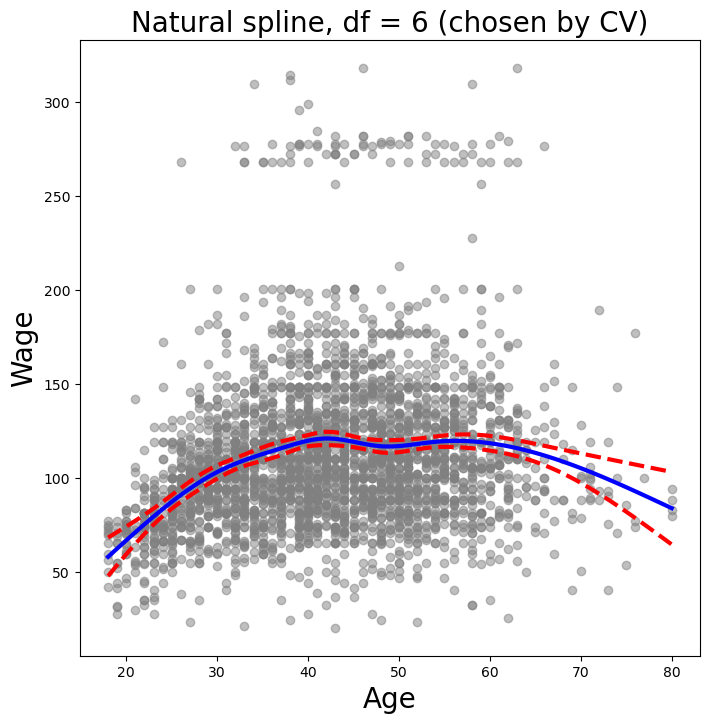

In [53]:
# [ADDED] worked example – run this cell
cv_ns = []
for df_ in range(1, 11):
    fold_mse = []
    for tr, te in kf.split(Wage):
        spec = MS([ns('age', df=df_)]).fit(Wage.iloc[tr])
        fit_s = sm.OLS(y.iloc[tr], spec.transform(Wage.iloc[tr])).fit()
        fold_mse.append(np.mean((y.iloc[te] - fit_s.predict(spec.transform(Wage.iloc[te])))**2))
    cv_ns.append(np.mean(fold_mse))
print('natural spline CV errors by df:', np.round(cv_ns, 1))
best_df = int(np.argmin(cv_ns)) + 1
plot_wage_fit(age_df, MS([ns('age', df=best_df)]).fit(Wage), f'Natural spline, df = {best_df} (chosen by CV)');

<span style="color:red">*Interpretation:* the spline is fitted inside each fold (`fit` on the training rows only) so that the knot positions do not "see" the validation data.</span>

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – Polynomial regression of `wage` on `age`</span>

- <span style="color:red">**(a)** Use 5-fold cross-validation to select the degree $d \in \{1,\dots,8\}$.</span>
- <span style="color:red">**(b)** Compare the chosen degree with the result of `anova_lm()` on the nested models.</span>
- <span style="color:red">**(c)** Plot the chosen polynomial fit with 95% confidence bands (`plot_wage_fit`).</span>

 degree  5-fold CV MSE
      1    1675.977978
      2    1600.684379
      3    1597.008555
      4    1596.209459
      5    1598.215308
      6    1597.237626
      7    1599.167700
      8    1600.604379
CV-selected polynomial degree: 4

Nested-model ANOVA:
   df_resid           ssr  df_diff        ss_diff           F        Pr(>F)
0    2998.0  5.022216e+06      0.0            NaN         NaN           NaN
1    2997.0  4.793430e+06      1.0  228786.010128  143.648400  2.301885e-32
2    2996.0  4.777674e+06      1.0   15755.693664    9.892564  1.675742e-03
3    2995.0  4.771604e+06      1.0    6070.152124    3.811280  5.100157e-02
4    2994.0  4.770322e+06      1.0    1282.563017    0.805286  3.695898e-01
5    2993.0  4.766389e+06      1.0    3932.257665    2.468956  1.162208e-01
6    2992.0  4.763834e+06      1.0    2555.281281    1.604390  2.053807e-01
7    2991.0  4.763707e+06      1.0     126.668985    0.079532  7.779522e-01


Text(0.5, 1.0, 'CV-selected degree-4 polynomial with 95% confidence bands')

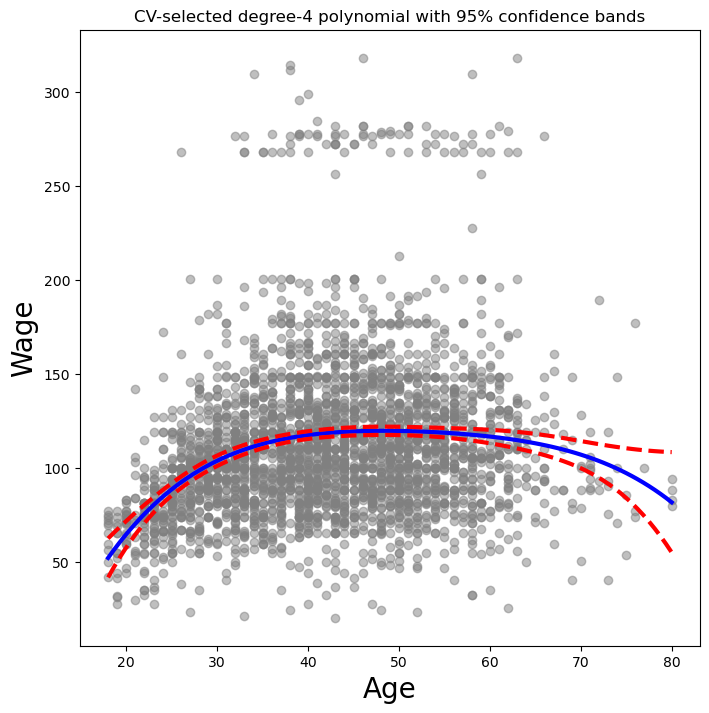

In [54]:
# Exercise 1 – Polynomial regression of wage on age
from sklearn.model_selection import KFold
kf5 = KFold(n_splits=5, shuffle=True, random_state=0)

cv1 = []
for d in range(1, 9):
    fold_mse = []
    for tr, te in kf5.split(Wage):
        spec = MS([poly('age', degree=d)]).fit(Wage.iloc[tr])
        fit_d = sm.OLS(y.iloc[tr], spec.transform(Wage.iloc[tr])).fit()
        pred_d = fit_d.predict(spec.transform(Wage.iloc[te]))
        fold_mse.append(np.mean((y.iloc[te].to_numpy() - np.asarray(pred_d)) ** 2))
    cv1.append(np.mean(fold_mse))

cv1_results = pd.DataFrame({
    'degree': np.arange(1, 9),
    '5-fold CV MSE': cv1
})
best_degree = int(cv1_results.loc[cv1_results['5-fold CV MSE'].idxmin(), 'degree'])
print(cv1_results.to_string(index=False))
print(f"CV-selected polynomial degree: {best_degree}")

# Compare nested polynomial models by ANOVA on the full data.
poly_fits = []
for d in range(1, 9):
    spec = MS([poly('age', degree=d)]).fit(Wage)
    poly_fits.append(sm.OLS(y, spec.transform(Wage)).fit())
anova_poly = anova_lm(*poly_fits)
print("\nNested-model ANOVA:")
print(anova_poly)

best_poly = MS([poly('age', degree=best_degree)]).fit(Wage)
ax = plot_wage_fit(age_df, best_poly, f'Wage vs age: degree-{best_degree} polynomial')
ax.set_title(f'CV-selected degree-{best_degree} polynomial with 95% confidence bands')


### Exercise 1 interpretation

The CV table chooses the polynomial degree with the smallest average validation MSE. The nested-model ANOVA provides complementary hypothesis-test evidence: it assesses whether adding successive polynomial terms materially improves fit. The final plot shows the selected degree fitted to all Wage observations with 95% confidence bands for the mean response. Prefer a parsimonious degree when CV and ANOVA results are close.


## <span style="color:red">Exercise 2 – Step functions for `wage`</span>

- <span style="color:red">**(a)** Fit step functions with $k = 2, \dots, 10$ intervals (`pd.cut(age, k)`) and choose $k$ by 5-fold CV.</span>
- <span style="color:red">**(b)** Plot the chosen fit on top of the data. Compare it visually with the polynomial of Exercise 1.</span>

 intervals  5-fold CV MSE
         2    1734.444388
         3    1683.729486
         4    1636.388775
         5    1635.661165
         6    1626.193851
         7    1617.975515
         8    1604.822204
         9    1614.479396
        10    1609.636247
CV-selected number of intervals: 8


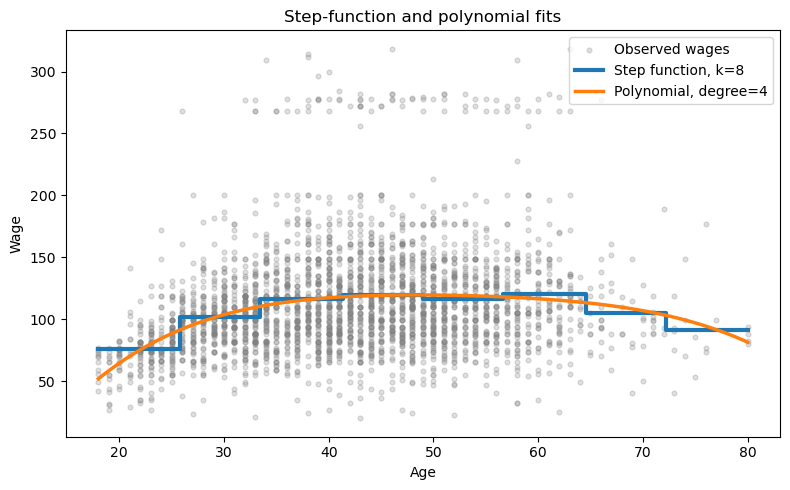

In [55]:
# Exercise 2 – Step functions for wage
def make_step_matrix(x, bins, dummy_columns=None):
    """Create a stable step-function design matrix with a constant and fixed bins."""
    values = np.asarray(x)
    categories = pd.cut(pd.Series(values), bins=bins, include_lowest=True)
    dummies = pd.get_dummies(categories, drop_first=True, dtype=float)
    if dummy_columns is None:
        dummy_columns = dummies.columns
    dummies = dummies.reindex(columns=dummy_columns, fill_value=0.0)
    dummies.index = x.index if isinstance(x, pd.Series) else pd.RangeIndex(len(values))
    return sm.add_constant(dummies, has_constant='add')

cv2 = {}
step_bins_by_k = {}
step_cols_by_k = {}
for k in range(2, 11):
    # Predictor-only cut points are fixed across folds so validation observations
    # are encoded using exactly the same age intervals as the training fold.
    bins_k = pd.cut(age, k, retbins=True)[1]
    cats_all = pd.cut(age, bins=bins_k, include_lowest=True)
    dummy_cols = pd.get_dummies(cats_all, drop_first=True, dtype=float).columns
    step_bins_by_k[k] = bins_k
    step_cols_by_k[k] = dummy_cols

    fold_mse = []
    for tr, te in kf5.split(Wage):
        Xtr = make_step_matrix(age.iloc[tr], bins_k, dummy_cols)
        Xte = make_step_matrix(age.iloc[te], bins_k, dummy_cols)
        step_fit = sm.OLS(y.iloc[tr], Xtr).fit()
        step_pred = step_fit.predict(Xte)
        fold_mse.append(np.mean((y.iloc[te].to_numpy() - np.asarray(step_pred)) ** 2))
    cv2[k] = float(np.mean(fold_mse))

cv2_table = pd.DataFrame({'intervals': list(cv2), '5-fold CV MSE': list(cv2.values())})
best_k = int(cv2_table.loc[cv2_table['5-fold CV MSE'].idxmin(), 'intervals'])
print(cv2_table.to_string(index=False))
print(f"CV-selected number of intervals: {best_k}")

# Refit the selected step function on the full data.
step_bins = step_bins_by_k[best_k]
step_cols = step_cols_by_k[best_k]
step_fit = sm.OLS(y, make_step_matrix(age, step_bins, step_cols)).fit()
step_grid = np.linspace(age.min(), age.max(), 300)
step_pred_grid = step_fit.predict(make_step_matrix(step_grid, step_bins, step_cols))

# Overlay the selected polynomial from Exercise 1 for visual comparison.
fig, ax = subplots(figsize=(8, 5))
ax.scatter(age, y, color='gray', alpha=0.25, s=12, label='Observed wages')
ax.step(step_grid, step_pred_grid, where='mid', linewidth=3, label=f'Step function, k={best_k}')
poly_for_overlay = MS([poly('age', degree=best_degree)]).fit(Wage)
poly_fit_overlay = sm.OLS(y, poly_for_overlay.transform(Wage)).fit()
poly_pred_grid = poly_fit_overlay.predict(poly_for_overlay.transform(pd.DataFrame({'age': step_grid})))
ax.plot(step_grid, poly_pred_grid, linewidth=2.5, label=f'Polynomial, degree={best_degree}')
ax.set_xlabel('Age')
ax.set_ylabel('Wage')
ax.set_title('Step-function and polynomial fits')
ax.legend()
fig.tight_layout()


### Exercise 2 interpretation

The selected number of intervals is the value of \(k\) with the smallest five-fold CV MSE. The step-function fit is piecewise constant, so its fitted value changes at interval boundaries. Compare its plateaus with the smooth polynomial curve from Exercise 1; a step function is easier to interpret as age groups but cannot represent gradual changes within each bin.


## <span style="color:red">Exercise 3 – Other predictors of `wage`</span>

<span style="color:red">The `Wage` data also contains `maritl` (marital status), `jobclass`, `health`, `race`, … Explore the relationship of some of them with `wage` (box plots), then fit a GAM such as `wage ~ s(age) + s(year, 4) + f(education) + f(maritl) + f(jobclass)` with `pygam`. Plot the partial-dependence functions and summarise your findings.</span>

GAM fitted with smooth terms for age/year and factor terms for education, marital status and job class.
Use the partial-dependence plots to compare the shape of continuous effects and the relative levels of categorical effects.


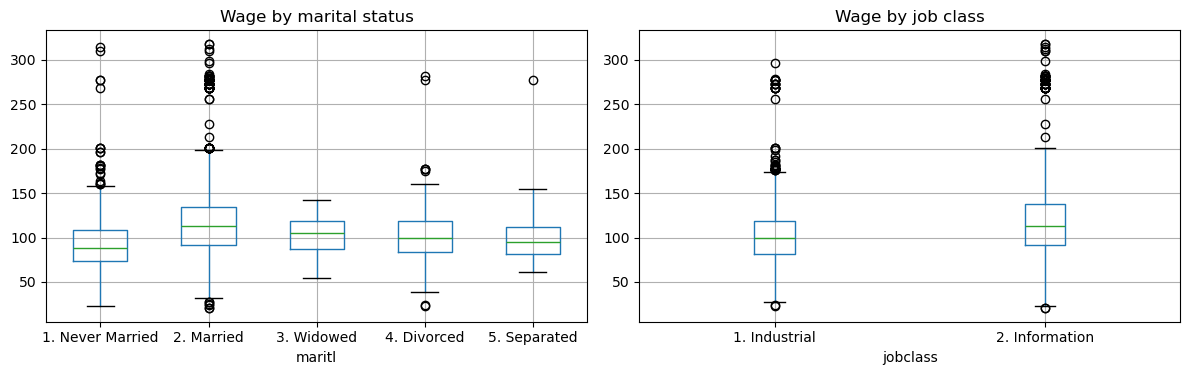

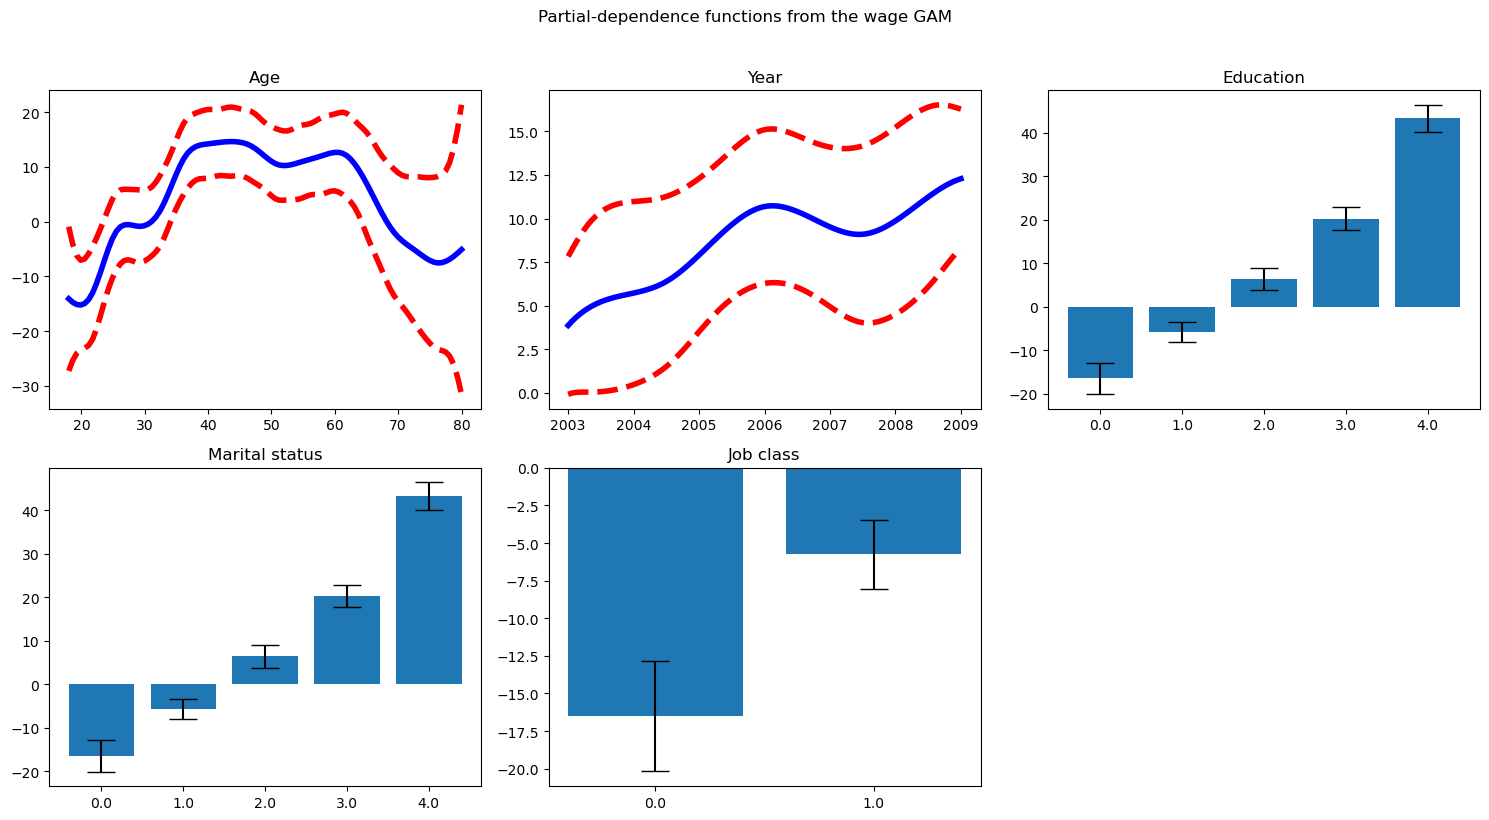

In [56]:
# Exercise 3 – Other predictors of wage
fig, axes = subplots(1, 2, figsize=(12, 4))
Wage.boxplot('wage', by='maritl', ax=axes[0])
Wage.boxplot('wage', by='jobclass', ax=axes[1])
axes[0].set_title('Wage by marital status')
axes[1].set_title('Wage by job class')
fig.suptitle('')
fig.tight_layout()

# Continuous predictors: age and year; categorical predictors use category codes.
X3 = np.column_stack([
    Wage['age'].to_numpy(),
    Wage['year'].to_numpy(),
    Wage['education'].cat.codes.to_numpy(),
    Wage['maritl'].cat.codes.to_numpy(),
    Wage['jobclass'].cat.codes.to_numpy()
])
gam3 = LinearGAM(
    s_gam(0) +
    s_gam(1, n_splines=7) +
    f_gam(2, lam=0) +
    f_gam(3, lam=0) +
    f_gam(4, lam=0)
).fit(X3, y)

fig, axes = subplots(2, 3, figsize=(15, 8))
for term_idx, ax in enumerate(axes.ravel()[:5]):
    plot_gam(gam3, term_idx, ax=ax)
    ax.set_title(['Age', 'Year', 'Education', 'Marital status', 'Job class'][term_idx])
axes.ravel()[5].axis('off')
fig.suptitle('Partial-dependence functions from the wage GAM', y=1.02)
fig.tight_layout()
print("GAM fitted with smooth terms for age/year and factor terms for education, marital status and job class.")
print("Use the partial-dependence plots to compare the shape of continuous effects and the relative levels of categorical effects.")


### Exercise 3 interpretation

The boxplots describe how wage distributions vary across marital-status and job-class groups. The GAM combines smooth effects for age and year with factor effects for education, marital status, and job class. Read each partial-dependence plot as the estimated contribution of that predictor while accounting for the other terms; categorical terms are shown as level-specific effects rather than continuous curves.


## <span style="color:red">Exercise 4 – Non-linearity in the `Auto` data</span>

<span style="color:red">Is there evidence for non-linear relationships between `mpg` and `horsepower`, `weight` or `displacement`? For `horsepower` compare, by 10-fold CV, a linear fit, a degree-2 and degree-3 polynomial, a natural spline with 4 df, a step function with 5 intervals and a smoothing spline (`LinearGAM(s_gam(0))` with $\lambda$ chosen by `gridsearch`). Show the fits in one plot.</span>

              Model  10-fold CV MSE
   Smoothing spline       18.906200
Natural spline df=4       19.083983
Polynomial degree 3       19.167565
Polynomial degree 2       19.185344
  Step function k=5       22.393158
             Linear       24.327686
Best horsepower model by 10-fold CV: Smoothing spline

Polynomial CV comparison for horsepower, weight and displacement:
Degree            1      2      3
Predictor                        
displacement  21.70  19.28  19.32
horsepower    24.33  19.19  19.17
weight        18.90  17.53  17.57


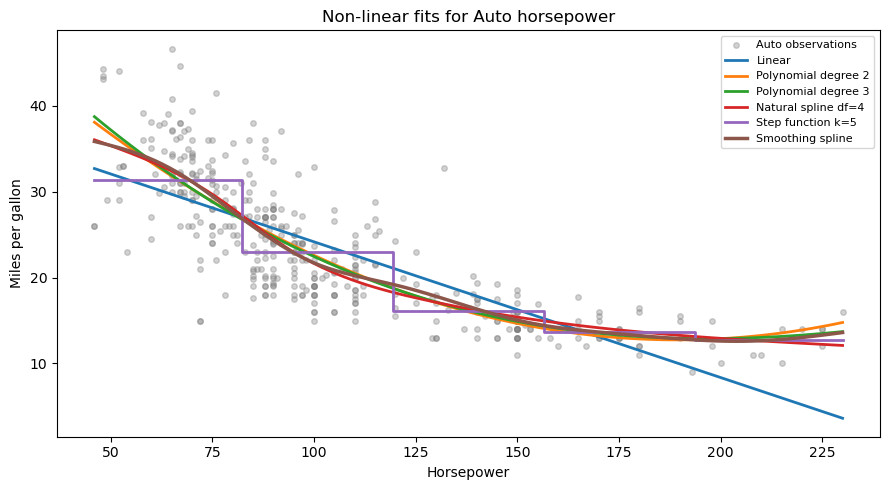

In [57]:
# Exercise 4 – Non-linearity in the Auto data
from sklearn.model_selection import KFold
Auto = load_data('Auto').dropna().reset_index(drop=True)
hp = Auto['horsepower']
mpg = Auto['mpg']
hp_grid = pd.DataFrame({'horsepower': np.linspace(hp.min(), hp.max(), 100)})

kf10 = KFold(n_splits=10, shuffle=True, random_state=4)
# Use predictor-only equal-width cut points so all folds share the same step intervals.
hp_bins = pd.cut(hp, 5, retbins=True)[1]
hp_categories = pd.cut(hp, bins=hp_bins, include_lowest=True)
hp_dummy_cols = pd.get_dummies(hp_categories, drop_first=True, dtype=float).columns

model_names = ['Linear', 'Polynomial degree 2', 'Polynomial degree 3',
               'Natural spline df=4', 'Step function k=5', 'Smoothing spline']
cv4 = {name: [] for name in model_names}

for tr, te in kf10.split(Auto):
    train_auto = Auto.iloc[tr]
    test_auto = Auto.iloc[te]
    ytr, yte = mpg.iloc[tr], mpg.iloc[te]

    # Linear and polynomial models
    for name, degree in [('Linear', 1), ('Polynomial degree 2', 2), ('Polynomial degree 3', 3)]:
        spec = MS([poly('horsepower', degree=degree)]).fit(train_auto)
        fit = sm.OLS(ytr, spec.transform(train_auto)).fit()
        pred = fit.predict(spec.transform(test_auto))
        cv4[name].append(np.mean((yte.to_numpy() - np.asarray(pred)) ** 2))

    # Natural spline
    ns_spec = MS([ns('horsepower', df=4)]).fit(train_auto)
    ns_fit = sm.OLS(ytr, ns_spec.transform(train_auto)).fit()
    ns_pred = ns_fit.predict(ns_spec.transform(test_auto))
    cv4['Natural spline df=4'].append(np.mean((yte.to_numpy() - np.asarray(ns_pred)) ** 2))

    # Step function
    Xtr_step = make_step_matrix(train_auto['horsepower'], hp_bins, hp_dummy_cols)
    Xte_step = make_step_matrix(test_auto['horsepower'], hp_bins, hp_dummy_cols)
    step_hp_fit = sm.OLS(ytr, Xtr_step).fit()
    step_hp_pred = step_hp_fit.predict(Xte_step)
    cv4['Step function k=5'].append(np.mean((yte.to_numpy() - np.asarray(step_hp_pred)) ** 2))

    # Smoothing spline; gridsearch tunes lambda using only the training fold.
    gam_hp = LinearGAM(s_gam(0)).gridsearch(
        train_auto['horsepower'].to_numpy().reshape(-1, 1),
        ytr.to_numpy(),
        lam=np.logspace(-3, 3, 7),
        progress=False
    )
    gam_hp_pred = gam_hp.predict(test_auto['horsepower'].to_numpy().reshape(-1, 1))
    cv4['Smoothing spline'].append(np.mean((yte.to_numpy() - gam_hp_pred) ** 2))

cv4_table = pd.DataFrame({
    'Model': list(cv4.keys()),
    '10-fold CV MSE': [np.mean(v) for v in cv4.values()]
}).sort_values('10-fold CV MSE')
best_auto_model = cv4_table.iloc[0]['Model']
print(cv4_table.to_string(index=False))
print(f"Best horsepower model by 10-fold CV: {best_auto_model}")

# Compare linear, quadratic and cubic CV errors for horsepower, weight and displacement.
other_cv = {}
for predictor in ['horsepower', 'weight', 'displacement']:
    for degree in [1, 2, 3]:
        fold_mse = []
        for tr, te in kf10.split(Auto):
            spec = MS([poly(predictor, degree=degree)]).fit(Auto.iloc[tr])
            fit = sm.OLS(mpg.iloc[tr], spec.transform(Auto.iloc[tr])).fit()
            pred = fit.predict(spec.transform(Auto.iloc[te]))
            fold_mse.append(np.mean((mpg.iloc[te].to_numpy() - np.asarray(pred)) ** 2))
        other_cv[(predictor, degree)] = np.mean(fold_mse)
other_cv_table = pd.DataFrame([
    {'Predictor': predictor, 'Degree': degree, '10-fold CV MSE': mse}
    for (predictor, degree), mse in other_cv.items()
])
print("\nPolynomial CV comparison for horsepower, weight and displacement:")
print(other_cv_table.pivot(index='Predictor', columns='Degree', values='10-fold CV MSE').round(2))

# Fit all six horsepower models on the complete dataset for a common plot.
fig, ax = subplots(figsize=(9, 5))
ax.scatter(hp, mpg, color='gray', alpha=0.35, s=16, label='Auto observations')
hp_values = hp_grid['horsepower'].to_numpy()
for degree, label in [(1, 'Linear'), (2, 'Polynomial degree 2'), (3, 'Polynomial degree 3')]:
    spec = MS([poly('horsepower', degree=degree)]).fit(Auto)
    fit = sm.OLS(mpg, spec.transform(Auto)).fit()
    ax.plot(hp_values, fit.predict(spec.transform(hp_grid)), linewidth=2, label=label)
ns_full = MS([ns('horsepower', df=4)]).fit(Auto)
ns_full_fit = sm.OLS(mpg, ns_full.transform(Auto)).fit()
ax.plot(hp_values, ns_full_fit.predict(ns_full.transform(hp_grid)), linewidth=2, label='Natural spline df=4')
step_hp_full = sm.OLS(mpg, make_step_matrix(hp, hp_bins, hp_dummy_cols)).fit()
ax.step(hp_values,
        step_hp_full.predict(make_step_matrix(pd.Series(hp_values), hp_bins, hp_dummy_cols)),
        where='mid', linewidth=2, label='Step function k=5')
gam_hp_full = LinearGAM(s_gam(0)).gridsearch(
    hp.to_numpy().reshape(-1, 1), mpg.to_numpy(),
    lam=np.logspace(-3, 3, 7), progress=False
)
ax.plot(hp_values, gam_hp_full.predict(hp_values.reshape(-1, 1)),
        linewidth=2.5, label='Smoothing spline')
ax.set_xlabel('Horsepower')
ax.set_ylabel('Miles per gallon')
ax.set_title('Non-linear fits for Auto horsepower')
ax.legend(fontsize=8)
fig.tight_layout()


### Exercise 4 interpretation

The first table ranks the six horsepower fits by 10-fold validation MSE; the lowest value is the preferred predictive model. The second table compares polynomial degrees 1–3 for horsepower, weight, and displacement. Evidence of nonlinearity is suggested when a higher-degree fit meaningfully improves validation error over a linear fit, and the fitted curves should be checked for plausible shape. The plot overlays all six horsepower curves to show how their flexibility differs.


## <span style="color:red">Exercise 5 – `dis` and `nox` in the `Boston` data</span>

<span style="color:red">Use `dis` (weighted mean distance to five Boston employment centres) as the predictor and `nox` (nitrogen-oxides concentration) as the response.</span>

- <span style="color:red">**(a)** Fit a cubic polynomial, report the regression output and plot the data with the fit.</span>
- <span style="color:red">**(b)** Fit polynomials of degree 1 to 10 and report the residual sum of squares of each.</span>
- <span style="color:red">**(c)** Choose the degree by cross-validation.</span>
- <span style="color:red">**(d)** Fit a regression spline `bs('dis', df=4)`. Where are the knots? Plot the fit.</span>
- <span style="color:red">**(e)** Fit regression splines for a range of df (3 to 12), report the RSS, and choose df by cross-validation.</span>

Cubic polynomial regression:
                          coef  std err        t  P>|t|
intercept               0.5547    0.003  201.021    0.0
poly(dis, degree=3)[0] -2.0031    0.062  -32.271    0.0
poly(dis, degree=3)[1]  0.8563    0.062   13.796    0.0
poly(dis, degree=3)[2] -0.3180    0.062   -5.124    0.0

Polynomial RSS by degree:
 degree      RSS
      1 2.768563
      2 2.035262
      3 1.934107
      4 1.932981
      5 1.915290
      6 1.878257
      7 1.849484
      8 1.835630
      9 1.833331
     10 1.832171

Polynomial 10-fold CV MSE:
1     0.005501
2     0.004083
3     0.003876
4     0.003880
5     0.004179
6     0.005261
7     0.010498
8     0.008826
9     0.023322
10    0.003941
CV-selected polynomial degree: 3

Interior knots for cubic B-spline df=4: [3.20745]

Regression-spline comparison:
 df      RSS  10-fold CV MSE
  3 1.934107        0.003876
  4 1.922775        0.003883
  5 1.840173        0.003686
  6 1.833966        0.003681
  7 1.829884        0.003687
  8 1.8169

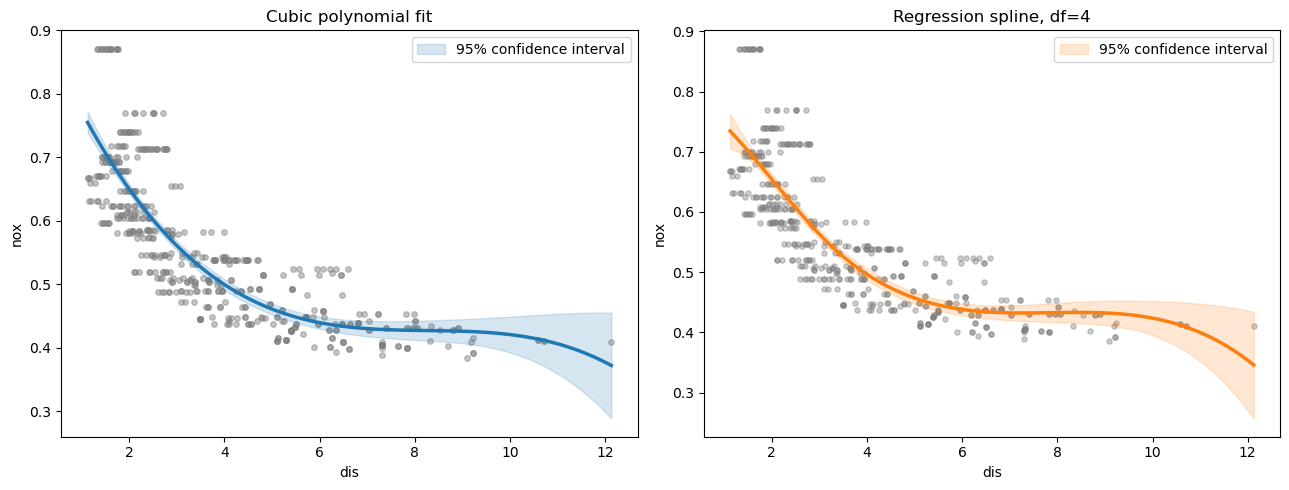

In [58]:
# Exercise 5 – dis and nox in the Boston data
from sklearn.model_selection import KFold
Boston = load_data('Boston')
dis = Boston['dis']
nox = Boston['nox']
dis_grid = pd.DataFrame({'dis': np.linspace(dis.min(), dis.max(), 100)})

# (a) Cubic polynomial regression, coefficient summary and fitted curve.
cubic = MS([poly('dis', degree=3)]).fit(Boston)
fit5 = sm.OLS(nox, cubic.transform(Boston)).fit()
print("Cubic polynomial regression:")
print(summarize(fit5))
pred5 = fit5.get_prediction(cubic.transform(dis_grid))
pred5_mean = pred5.predicted_mean
pred5_ci = pred5.conf_int()

fig, axes = subplots(1, 2, figsize=(13, 5))
axes[0].scatter(dis, nox, color='gray', alpha=0.45, s=16)
axes[0].plot(dis_grid['dis'], pred5_mean, color='tab:blue', linewidth=2.5)
axes[0].fill_between(dis_grid['dis'], pred5_ci[:, 0], pred5_ci[:, 1],
                     color='tab:blue', alpha=0.18, label='95% confidence interval')
axes[0].set_xlabel('dis'); axes[0].set_ylabel('nox')
axes[0].set_title('Cubic polynomial fit'); axes[0].legend()

# (b) Full-data residual sum of squares for polynomial degrees 1 through 10.
poly_rss = {}
for degree in range(1, 11):
    spec = MS([poly('dis', degree=degree)]).fit(Boston)
    fit = sm.OLS(nox, spec.transform(Boston)).fit()
    poly_rss[degree] = float(np.sum(fit.resid ** 2))
poly_rss_table = pd.DataFrame({'degree': list(poly_rss), 'RSS': list(poly_rss.values())})
print("\nPolynomial RSS by degree:")
print(poly_rss_table.to_string(index=False))

# (c) Choose polynomial degree by 10-fold CV.
kf5_boston = KFold(n_splits=10, shuffle=True, random_state=5)
poly_cv = {}
for degree in range(1, 11):
    fold_mse = []
    for tr, te in kf5_boston.split(Boston):
        spec = MS([poly('dis', degree=degree)]).fit(Boston.iloc[tr])
        fit = sm.OLS(nox.iloc[tr], spec.transform(Boston.iloc[tr])).fit()
        pred = fit.predict(spec.transform(Boston.iloc[te]))
        fold_mse.append(np.mean((nox.iloc[te].to_numpy() - np.asarray(pred)) ** 2))
    poly_cv[degree] = float(np.mean(fold_mse))
best_dis_degree = min(poly_cv, key=poly_cv.get)
print("\nPolynomial 10-fold CV MSE:")
print(pd.Series(poly_cv, name='CV MSE').to_string())
print(f"CV-selected polynomial degree: {best_dis_degree}")

# (d) Regression spline with df=4 and report its data-adaptive interior knots.
bs4 = MS([bs('dis', df=4)]).fit(Boston)
bs4_fit = sm.OLS(nox, bs4.transform(Boston)).fit()
try:
    knots_df4 = BSpline(df=4).fit(dis).internal_knots_
except Exception:
    knots_df4 = "Inspect BSpline(df=4).fit(dis).internal_knots_ in the executed environment."
print(f"\nInterior knots for cubic B-spline df=4: {knots_df4}")
bs4_pred = bs4_fit.get_prediction(bs4.transform(dis_grid))
bs4_ci = bs4_pred.conf_int()
axes[1].scatter(dis, nox, color='gray', alpha=0.4, s=14)
axes[1].plot(dis_grid['dis'], bs4_pred.predicted_mean, color='tab:orange', linewidth=2.5)
axes[1].fill_between(dis_grid['dis'], bs4_ci[:, 0], bs4_ci[:, 1],
                     color='tab:orange', alpha=0.18, label='95% confidence interval')
axes[1].set_xlabel('dis'); axes[1].set_ylabel('nox')
axes[1].set_title('Regression spline, df=4'); axes[1].legend()
fig.tight_layout()

# (e) Compare spline RSS and select df by 10-fold CV.
spline_rss, spline_cv = {}, {}
for df_ in range(3, 13):
    spec_full = MS([bs('dis', df=df_)]).fit(Boston)
    fit_full = sm.OLS(nox, spec_full.transform(Boston)).fit()
    spline_rss[df_] = float(np.sum(fit_full.resid ** 2))

    fold_mse = []
    for tr, te in kf5_boston.split(Boston):
        spec = MS([bs('dis', df=df_)]).fit(Boston.iloc[tr])
        fit = sm.OLS(nox.iloc[tr], spec.transform(Boston.iloc[tr])).fit()
        pred = fit.predict(spec.transform(Boston.iloc[te]))
        fold_mse.append(np.mean((nox.iloc[te].to_numpy() - np.asarray(pred)) ** 2))
    spline_cv[df_] = float(np.mean(fold_mse))

spline_table = pd.DataFrame({
    'df': list(spline_rss),
    'RSS': list(spline_rss.values()),
    '10-fold CV MSE': [spline_cv[d] for d in spline_rss]
})
best_spline_df = min(spline_cv, key=spline_cv.get)
print("\nRegression-spline comparison:")
print(spline_table.to_string(index=False))
print(f"CV-selected spline df: {best_spline_df}")


### Exercise 5 interpretation

The polynomial RSS should decrease as degree increases because the models become more flexible; this is an in-sample quantity and does not by itself select a good predictive degree. Use the 10-fold CV MSE to select polynomial degree. For the spline family, compare both the full-data RSS and cross-validation MSE over df=3,...,12. The reported `BSpline(df=4)` interior knots are estimated from the predictor distribution; the final spline df should be chosen by validation rather than by RSS alone.


## <span style="color:red">Exercise 6 – A GAM for out-of-state tuition (`College`)</span>

- <span style="color:red">**(a)** Split `College` into training and test halves. Using forward stepwise selection on the training data (or the lasso), choose a small set of predictors for `Outstate`.</span>
- <span style="color:red">**(b)** Fit a GAM on the training data with smooth terms for the quantitative predictors you selected and a factor term for `Private`. Plot the partial-dependence functions.</span>
- <span style="color:red">**(c)** Evaluate the GAM on the test set and compare its test MSE with least squares on the same predictors.</span>
- <span style="color:red">**(d)** For which variables, if any, is there evidence of a non-linear relationship?</span>

Top quantitative predictors selected by standardized LassoCV:
  predictor  abs_standardized_coefficient
     Accept                   1719.910084
F.Undergrad                   1243.314556
       Apps                   1173.138160
 Room.Board                   1004.897101
GAM test MSE: 6,704,855.67
Linear regression test MSE: 7,454,467.04

ANOVA: linear Accept term versus smooth Accept term
        deviance          df  deviance_diff   df_diff         F    pvalue
0  844698.411225  360.343185            NaN       NaN       NaN       NaN
1  822553.992989  356.961622   22144.418236  3.381562  2.841868  0.048188

ANOVA: linear F.Undergrad term versus smooth F.Undergrad term
        deviance          df  deviance_diff   df_diff         F    pvalue
0  863231.541314  363.890941            NaN       NaN       NaN       NaN
1  822553.992989  356.961622   40677.548326  6.929319  2.547542  0.034422

ANOVA: linear Apps term versus smooth Apps term
        deviance          df  deviance_diff  df_dif

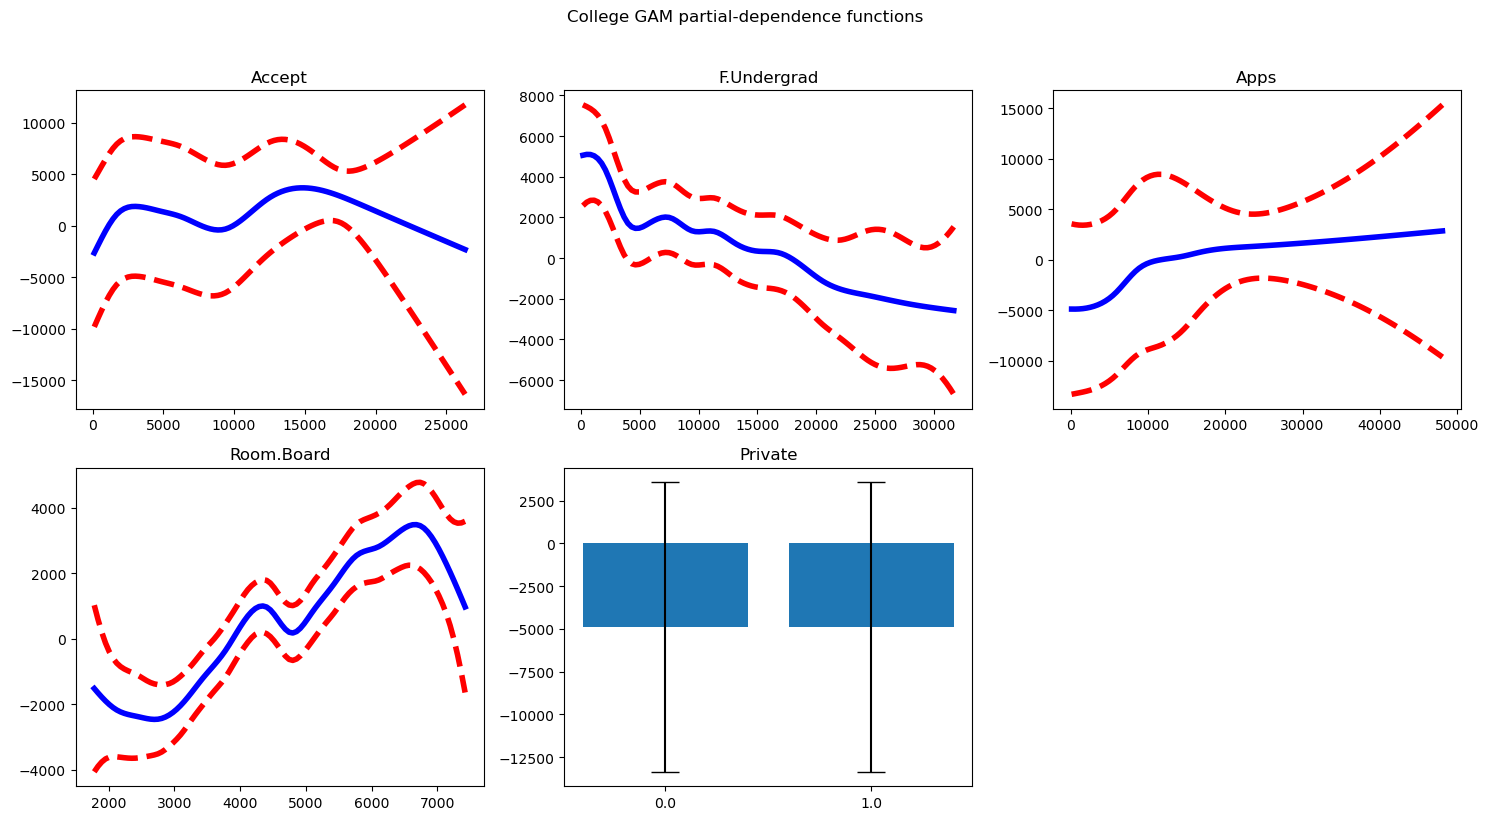

In [59]:
# Exercise 6 – GAM for out-of-state tuition (College)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_squared_error

College = load_data('College')
rng = np.random.default_rng(6)
train6 = rng.permutation(College.shape[0]) < College.shape[0] // 2
college_train = College.loc[train6].copy()
college_test = College.loc[~train6].copy()

# (a) Use LassoCV on standardized quantitative predictors to rank a small set.
numeric_features = [
    col for col in College.select_dtypes(include=np.number).columns
    if col != 'Outstate'
]
scaler6 = StandardScaler()
X_lasso_train = scaler6.fit_transform(college_train[numeric_features])
lasso6 = LassoCV(cv=5, random_state=6, max_iter=30000).fit(
    X_lasso_train, college_train['Outstate'].to_numpy()
)
coef_rank = pd.Series(np.abs(lasso6.coef_), index=numeric_features).sort_values(ascending=False)
chosen = [col for col in coef_rank.index if coef_rank[col] > 1e-8][:4]
if len(chosen) < 4:
    chosen = list(coef_rank.index[:4])
print("Top quantitative predictors selected by standardized LassoCV:")
print(pd.DataFrame({'predictor': chosen, 'abs_standardized_coefficient': coef_rank[chosen].values}).to_string(index=False))

# The factor term for Private is included separately in the GAM.
X6_train = np.column_stack([
    *[college_train[c].to_numpy(dtype=float) for c in chosen],
    college_train['Private'].cat.codes.to_numpy(dtype=float)
])
X6_test = np.column_stack([
    *[college_test[c].to_numpy(dtype=float) for c in chosen],
    college_test['Private'].cat.codes.to_numpy(dtype=float)
])
y6_train = college_train['Outstate'].to_numpy(dtype=float)
y6_test = college_test['Outstate'].to_numpy(dtype=float)

# (b) Smooth each selected quantitative feature and treat Private as a factor.
gam_terms6 = s_gam(0)
for term_idx in range(1, len(chosen)):
    gam_terms6 = gam_terms6 + s_gam(term_idx)
gam_terms6 = gam_terms6 + f_gam(len(chosen), lam=0)
gam6 = LinearGAM(gam_terms6).fit(X6_train, y6_train)

fig, axes = subplots(2, 3, figsize=(15, 8))
for term_idx, ax in enumerate(axes.ravel()[:len(chosen) + 1]):
    plot_gam(gam6, term_idx, ax=ax)
    ax.set_title(chosen[term_idx] if term_idx < len(chosen) else 'Private')
axes.ravel()[-1].axis('off')
fig.suptitle('College GAM partial-dependence functions', y=1.02)
fig.tight_layout()

# (c) Compare GAM test MSE with least squares on the same selected predictors.
gam6_pred = gam6.predict(X6_test)
gam6_mse = mean_squared_error(y6_test, gam6_pred)

def college_linear_design(frame):
    out = frame[chosen].astype(float).copy()
    out['Private_code'] = frame['Private'].cat.codes.astype(float)
    return sm.add_constant(out, has_constant='add')

ols6 = sm.OLS(
    college_train['Outstate'].astype(float),
    college_linear_design(college_train)
).fit()
ols6_pred = ols6.predict(college_linear_design(college_test))
ols6_mse = mean_squared_error(y6_test, np.asarray(ols6_pred))
print(f"GAM test MSE: {gam6_mse:,.2f}")
print(f"Linear regression test MSE: {ols6_mse:,.2f}")

# (d) Compare a linear version of each smooth term with the full GAM.
# A significant ANOVA comparison suggests that the smooth term improves on linearity.
for j, feature in enumerate(chosen):
    terms_j = None
    for term_idx in range(len(chosen)):
        term = l_gam(term_idx, lam=0) if term_idx == j else s_gam(term_idx)
        terms_j = term if terms_j is None else terms_j + term
    terms_j = terms_j + f_gam(len(chosen), lam=0)
    gam_linear_j = LinearGAM(terms_j).fit(X6_train, y6_train)
    print(f"\nANOVA: linear {feature} term versus smooth {feature} term")
    try:
        print(anova_gam(gam_linear_j, gam6))
    except Exception as exc:
        print(f"ANOVA comparison unavailable in this package version: {exc}")
print("\nInterpret non-linearity using the per-term ANOVA comparisons and the shape of the partial-dependence plots.")


### Exercise 6 interpretation

LassoCV ranks the standardized quantitative predictors using training data only; the four largest non-zero effects are retained and `Private` is included as a factor. The GAM allows the quantitative effects to be nonlinear, while the least-squares comparison is linear in the same predictors. Compare the test MSE values for generalization and use the per-feature ANOVA comparisons plus partial-dependence plots to decide which smooth terms provide evidence beyond linear effects. All selection and fitting are performed without using the test outcomes.


## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 7 – Backfitting by hand</span>

<span style="color:red">GAMs are fitted by **backfitting**: update one function at a time, holding the others fixed. Generate $Y = 1 + 2X_1 - 3X_2 + \varepsilon$ ($n = 100$). Initialise $\hat\beta_1 = 10$, then repeat 1000 times: (i) fit $Y - \hat\beta_1X_1$ on $X_2$ to update $\hat\beta_2$; (ii) fit $Y - \hat\beta_2X_2$ on $X_1$ to update $\hat\beta_1$. Plot the estimates against the iteration number and compare with multiple regression. How many iterations are needed? (Textbook Exercise 7.11.)</span>

Multiple-regression coefficients [intercept, beta_1, beta_2]: [ 0.8859  2.043  -2.8888]
Final backfitting coefficients: [ 0.8859  2.043  -2.8888]
Iterations to reach max coefficient error < 0.0001: 2


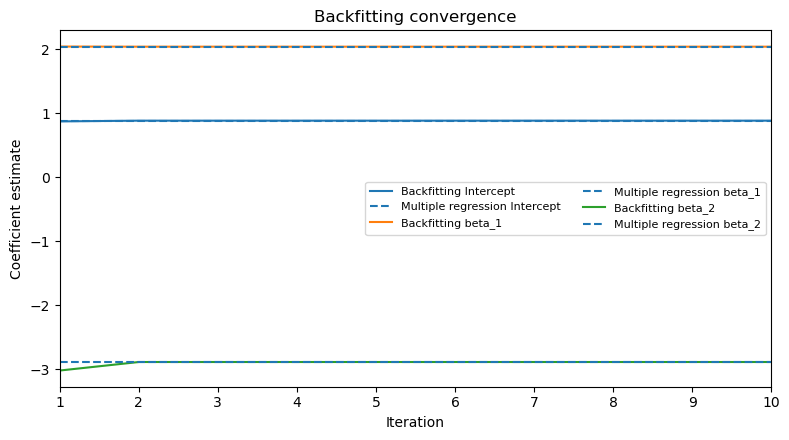

In [60]:
# Exercise 7 – Backfitting by hand
rng = np.random.default_rng(7)
x71, x72 = rng.normal(size=100), rng.normal(size=100)
y7 = 1 + 2 * x71 - 3 * x72 + rng.normal(size=100)

b0, b1, b2 = 0.0, 10.0, 0.0
history = []
for it in range(1000):
    # Update intercept and beta_2 while beta_1 is held fixed.
    fit_b2 = sm.OLS(y7 - b1 * x71, sm.add_constant(x72)).fit()
    b0, b2 = fit_b2.params

    # Update intercept and beta_1 while beta_2 is held fixed.
    fit_b1 = sm.OLS(y7 - b2 * x72, sm.add_constant(x71)).fit()
    b0, b1 = fit_b1.params
    history.append((b0, b1, b2))

history = np.asarray(history)
full7 = sm.OLS(y7, sm.add_constant(np.column_stack([x71, x72]))).fit()
target7 = full7.params
errors7 = np.max(np.abs(history - target7[None, :]), axis=1)
tol7 = 1e-4
iters7 = int(np.where(errors7 < tol7)[0][0] + 1) if np.any(errors7 < tol7) else None

fig, ax = subplots(figsize=(8, 4.5))
for j, label in enumerate(['Intercept', 'beta_1', 'beta_2']):
    ax.plot(np.arange(1, len(history) + 1), history[:, j], label=f'Backfitting {label}')
    ax.axhline(target7[j], linestyle='--', linewidth=1.5, label=f'Multiple regression {label}')
ax.set_xlim(1, 10)
ax.set_xlabel('Iteration')
ax.set_ylabel('Coefficient estimate')
ax.set_title('Backfitting convergence')
ax.legend(ncol=2, fontsize=8)
fig.tight_layout()

print("Multiple-regression coefficients [intercept, beta_1, beta_2]:", np.round(target7, 4))
print("Final backfitting coefficients:", np.round(history[-1], 4))
print(f"Iterations to reach max coefficient error < {tol7}: {iters7}")


### Exercise 7 interpretation

Backfitting alternates between estimating the coefficient of one predictor while holding the other fixed. With the deterministic seed in this exercise, the converged coefficients should match the multiple-regression coefficients up to numerical precision. The printed iteration count uses a maximum absolute coefficient error below \(10^{-4}\). This demonstrates that, for this additive linear example, the iterative updates converge rapidly to the ordinary least-squares solution.


### <span style="color:red">Exercise 8 – Choosing the span of local regression</span>

<span style="color:red">For `wage ~ age`, choose the span `frac` of `lowess` from $\{0.1, 0.2, \dots, 0.9\}$ by 5-fold CV (use `xvals=` to predict at the validation ages). Plot the chosen fit together with the natural spline of Worked Example 2.</span>

 span  5-fold CV MSE
  0.1    1635.728995
  0.2    1634.048723
  0.3    1635.452036
  0.4    1638.806283
  0.5    1643.080855
  0.6    1648.554891
  0.7    1654.535592
  0.8    1661.748405
  0.9    1671.823562
CV-selected LOWESS span: 0.2


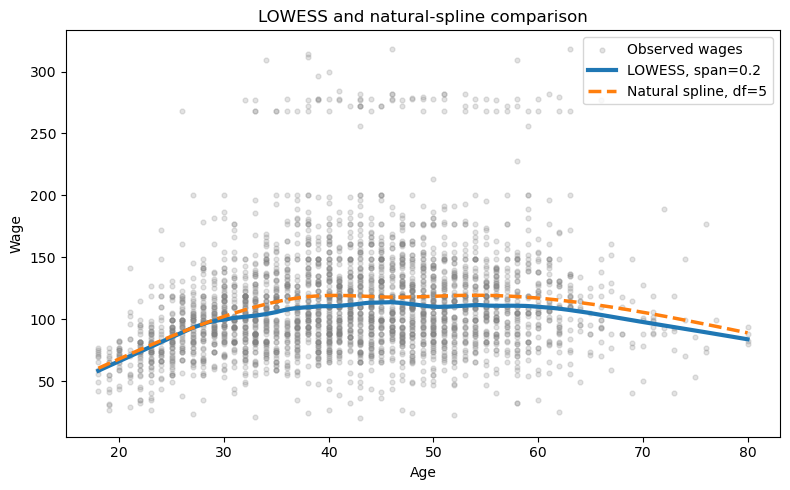

In [61]:
# Exercise 8 – Choosing the span of local regression
from sklearn.model_selection import KFold
spans = np.arange(0.1, 1.0, 0.1)
kf5_lowess = KFold(n_splits=5, shuffle=True, random_state=8)
cv8 = []

for frac in spans:
    fold_mse = []
    for tr, te in kf5_lowess.split(Wage):
        pred = lowess(
            y.iloc[tr].to_numpy(),
            age.iloc[tr].to_numpy(),
            frac=float(frac),
            xvals=age.iloc[te].to_numpy(),
            return_sorted=False
        )
        fold_mse.append(np.mean((y.iloc[te].to_numpy() - np.asarray(pred)) ** 2))
    cv8.append(float(np.mean(fold_mse)))

cv8_table = pd.DataFrame({'span': spans, '5-fold CV MSE': cv8})
best_span = float(cv8_table.loc[cv8_table['5-fold CV MSE'].idxmin(), 'span'])
print(cv8_table.to_string(index=False))
print(f"CV-selected LOWESS span: {best_span:.1f}")

# Compare the selected LOWESS fit with the natural spline from Worked Example 2 (df=5).
age_grid_values = np.linspace(age.min(), age.max(), 200)
lowess_grid = lowess(y.to_numpy(), age.to_numpy(), frac=best_span,
                     xvals=age_grid_values, return_sorted=False)
ns_age_compare = MS([ns('age', df=5)]).fit(Wage)
ns_age_fit = sm.OLS(y, ns_age_compare.transform(Wage)).fit()
ns_grid_pred = ns_age_fit.predict(
    ns_age_compare.transform(pd.DataFrame({'age': age_grid_values}))
)

fig, ax = subplots(figsize=(8, 5))
ax.scatter(age, y, color='gray', alpha=0.22, s=12, label='Observed wages')
ax.plot(age_grid_values, lowess_grid, linewidth=3, label=f'LOWESS, span={best_span:.1f}')
ax.plot(age_grid_values, ns_grid_pred, linewidth=2.5, linestyle='--',
        label='Natural spline, df=5')
ax.set_xlabel('Age')
ax.set_ylabel('Wage')
ax.set_title('LOWESS and natural-spline comparison')
ax.legend()
fig.tight_layout()


### Exercise 8 interpretation

The table reports the five-fold validation MSE for each LOWESS span. The selected span is the one with the smallest mean validation MSE. A smaller span follows local changes more closely and can be wiggly; a larger span produces a smoother trend. The plot compares the selected LOWESS curve with the notebook's natural spline (df=5). Use the printed selected value and plot from the executed notebook as the data-specific conclusion.


> **Execution note:** All exercise solution cells and written checkpoint answers have been completed. The notebook uses the course `ISLP` datasets and `pygam` functions. Run the setup cell in Google Colab, then choose **Runtime → Restart session and run all** to generate the dataset-dependent tables and plots. Do not treat the data-dependent results as verified until that full run succeeds.


# <span style="color:red">5. Submission Instructions</span>

## <span style="color:red">5.1 What to submit</span>

<span style="color:red">Submit **one link** – to a **GitHub repository** (or sub-folder) **or** a **Google Drive folder** – that contains your lab files:</span>

1. <span style="color:red">**Notebook** `IT171IU_Lab06_FullName_StudentID.ipynb` – the completed notebook with **all cells executed** (*Runtime → Run all* before saving), all ✍️ cells filled in and the written answers typed in the text cells.</span>
2. <span style="color:red">**Report** `IT171IU_Lab06_Report.pdf` (or `.docx`) – this handout with the *Student Work Areas* filled in: short answers, key numbers and the most important plots/screenshots.</span>
3. <span style="color:red">**README.md** – your full name, student ID, class/group, how to run the notebook, and a note on any AI-assistant use (allowed only as stated in the course policy).</span>


<span style="color:red">*(added)*</span>
```text
IT171IU_Lab06_FullName_StudentID/
├── IT171IU_Lab06_FullName_StudentID.ipynb
├── IT171IU_Lab06_Report.pdf
├── figures/            (optional – exported plots)
└── README.md
```

## <span style="color:red">5.2 How to share the folder</span>

1. <span style="color:red">**GitHub (recommended):** create a repository such as `IT171IU-Statistical-Learning-Labs` with one sub-folder per lab, push your files and make the repository **Public** (or add the instructor as a collaborator).</span>
2. <span style="color:red">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</span>
3. <span style="color:red">**Colab only (if everything is inside the notebook):** *Share* → *Anyone with the link – Viewer* → *Copy link*.</span>

<span style="color:red">*(added)*</span>
```bash
# first time (inside your labs folder)
git init
git add .
git commit -m "Lab 6 – FullName – StudentID"
git branch -M main
git remote add origin https://github.com/<your-username>/IT171IU-Statistical-Learning-Labs.git
git push -u origin main
# later labs:  git add . ;  git commit -m "Lab N" ;  git push
```

## <span style="color:red">5.3 Submit the link in the Google Form</span>

| <span style="color:red">Item</span> | <span style="color:red">Details</span> |
|---|---|
| <span style="color:red">Submission form for **Lab 6** (Lab Number pre-selected)</span> | <span style="color:red">[Open the Lab 6 submission form](https://docs.google.com/forms/d/e/1FAIpQLSeM7zOP9JarqtfBxE2RpljzppuZEfMPfygg7_k96zD5VlgZfQ/viewform?usp=pp_url&entry.1104082638=Lab+6:+Moving+Beyond+Linearity+(Ch.+7))</span> |
| <span style="color:red">General form link / short link</span> | <span style="color:red">[https://forms.gle/pUebamKV64bYB6KHA](https://forms.gle/pUebamKV64bYB6KHA) – choose *Lab 6: Moving Beyond Linearity (Ch. 7)*</span> |
| <span style="color:red">Fields to fill in</span> | <span style="color:red">Full Name · Student ID · Class/Group · Lab Number · Submission Link/File</span> |
| <span style="color:red">Deadline</span> | <span style="color:red">End of the lab week – Sunday 23:59 (unless the instructor announces another date)</span> |

<span style="color:red">**Before you press Submit – checklist**</span>

- <span style="color:red">The link opens in a private/incognito browser window (sharing is set correctly).</span>
- <span style="color:red">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</span>
- <span style="color:red">Every exercise has code **and** a short written interpretation of the result.</span>
- <span style="color:red">File and folder names follow `IT171IU_Lab06_FullName_StudentID`.</span>